# Abu Dhabi Air Pollution — Full EDA + ERA5 Weather Validation

**Scope:** This notebook uses only four files: the original OpenAQ daily pollution data, OpenAQ station metadata, ERA5 daily weather summaries, and ERA5 hourly weather. The annual dataset is intentionally excluded.

**Main goal:** Build the station-day master dataset first, then perform the EDA on that master dataset. The notebook keeps all original pollution observations and flags lower-support records rather than deleting them.

### What this notebook delivers
1. Master data with one row per station per calendar day, five pollutants, station coordinates, and daily weather.
2. A check that independently re-aggregates hourly ERA5 and compares it with the supplied daily weather file.
3. A full EDA: coverage, sampling support, distributions, station differences, temporal patterns, pollutant correlations, weather relationships, wind sectors, and statistical anomaly patterns.
4. A chronological train/validation/test partition of the master data for downstream modelling.
5. CSV tables, high-resolution figures, a PDF figure pack, a data dictionary, and one ZIP containing all inputs and outputs.

### Important interpretation rules
- Low reading support is a **quality limitation**, not automatic proof that a value is invalid.
- The main reliability analysis uses `readings >= 12`; a stricter `readings >= 18` sensitivity check is also reported. All rows remain in the master data.
- ERA5 values are gridded reanalysis estimates, not direct measurements at the pollution stations.
- The hourly weather file can validate the daily aggregation and describe the weather over an anomaly day. The OpenAQ daily pollution file does **not** identify the exact hour of a pollution spike, so hourly weather cannot identify the exact weather at the hour of detection.
- The supplied OpenAQ pollution CSV does not state pollutant units. Confirm units from source metadata before regulatory-threshold claims.

## Step 1 — Import libraries and set up output folders

Upload the four required CSV files manually into the Colab Files panel. This notebook does not open an upload dialog. It searches the working folder and `/content` for the files.

In [1]:
from pathlib import Path
import json
import math
import shutil
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)

# In Colab this is usually /content. When run locally, it is the current folder.
BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "abudhabi_openaq_eda_outputs"

# Start with clean output folders so old figures/tables from earlier runs are not mixed in.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
INPUT_DIR = OUTPUT_DIR / "input_files"
for folder in [OUTPUT_DIR, FIGURE_DIR, TABLE_DIR, INPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

POLLUTANTS = ["pm10", "no2", "so2", "o3", "co"]
POLLUTANT_LABELS = {
    "pm10": "PM10", "no2": "NO₂", "so2": "SO₂", "o3": "O₃", "co": "CO"
}
MIN_READINGS_MAIN = 12
MIN_READINGS_STRICT = 18

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "savefig.dpi": 180,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 12,
})

print("Working folder:", BASE_DIR)
print("Output folder:", OUTPUT_DIR)


Working folder: /content
Output folder: /content/abudhabi_openaq_eda_outputs


**Step 1 result:** The notebook is set up to save the master data, EDA tables, figures, and report in one output folder. Next, we load the four files used in this analysis.

## Step 2 — Load the four source files

Required files:
- `openaq_daily_all_stations.csv`
- `openaq_stations.csv`
- `openaq_station_weather_ERA5_daily.csv`
- `openaq_station_weather_ERA5_hourly.csv`

The annual dataset is not used.

In [2]:
def find_file(file_stem):
    """Find a manually uploaded CSV, including Colab names ending in (1)."""
    search_folders = [BASE_DIR, Path("/content")]
    matches = []
    for folder in search_folders:
        if folder.exists():
            matches.extend(folder.glob(file_stem + "*.csv"))
    matches = list({p.resolve() for p in matches})
    if not matches:
        raise FileNotFoundError(
            f"Cannot find {file_stem}*.csv. Upload the file into the Colab Files panel."
        )
    return max(matches, key=lambda p: p.stat().st_mtime)

DAILY_FILE = find_file("openaq_daily_all_stations")
STATIONS_FILE = find_file("openaq_stations")
WEATHER_DAILY_FILE = find_file("openaq_station_weather_ERA5_daily")
WEATHER_HOURLY_FILE = find_file("openaq_station_weather_ERA5_hourly")

print("OpenAQ daily:", DAILY_FILE.name)
print("Station metadata:", STATIONS_FILE.name)
print("ERA5 daily:", WEATHER_DAILY_FILE.name)
print("ERA5 hourly:", WEATHER_HOURLY_FILE.name)

daily_source = pd.read_csv(DAILY_FILE)
stations_source = pd.read_csv(STATIONS_FILE)
weather_daily_source = pd.read_csv(WEATHER_DAILY_FILE)
weather_hourly_source = pd.read_csv(WEATHER_HOURLY_FILE)

print("\nSource file dimensions")
print("Pollution:", daily_source.shape)
print("Stations:", stations_source.shape)
print("ERA5 daily:", weather_daily_source.shape)
print("ERA5 hourly:", weather_hourly_source.shape)
display(daily_source.head())

OpenAQ daily: openaq_daily_all_stations.csv
Station metadata: openaq_stations.csv
ERA5 daily: openaq_station_weather_ERA5_daily.csv
ERA5 hourly: openaq_station_weather_ERA5_hourly.csv

Source file dimensions
Pollution: (28714, 7)
Stations: (20, 5)
ERA5 daily: (11400, 15)
ERA5 hourly: (273600, 15)


,station_id,parameter,day,readings,mean,max,station
0,369953,no2,2022-10-29,13,15.474615,20.54,Bida Zayed-380554
1,369953,no2,2022-11-01,13,18.906923,26.59,Bida Zayed-380554
2,369953,no2,2022-11-02,14,20.468571,34.88,Bida Zayed-380554
3,369953,no2,2022-11-03,14,25.720000,38.80,Bida Zayed-380554
4,369953,no2,2022-11-04,13,24.105385,41.63,Bida Zayed-380554


**Step 2 result:** We have the original pollution observations, station coordinates, daily weather summaries, and hourly weather. The hourly file will be used to independently rebuild daily weather summaries and verify the day alignment.

## Step 3 — Inspect source structure and data quality

We inspect columns, data types, missing cells, exact duplicate rows, and key uniqueness before constructing the master table.

In [3]:
def make_schema_table(df, name):
    return pd.DataFrame({
        "source": name,
        "column": df.columns,
        "dtype": [str(df[c].dtype) for c in df.columns],
        "missing_count": [int(df[c].isna().sum()) for c in df.columns],
        "missing_percent": [round(df[c].isna().mean() * 100, 2) for c in df.columns],
        "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns],
    })

schema_table = pd.concat([
    make_schema_table(daily_source, "OpenAQ daily"),
    make_schema_table(stations_source, "Station metadata"),
    make_schema_table(weather_daily_source, "ERA5 daily"),
    make_schema_table(weather_hourly_source, "ERA5 hourly"),
], ignore_index=True)
display(schema_table)
print("Exact duplicate rows:")
print({
    "pollution": int(daily_source.duplicated().sum()),
    "stations": int(stations_source.duplicated().sum()),
    "weather_daily": int(weather_daily_source.duplicated().sum()),
    "weather_hourly": int(weather_hourly_source.duplicated().sum()),
})
schema_table.to_csv(TABLE_DIR / "source_schema_and_missingness.csv", index=False)

,source,column,dtype,missing_count,missing_percent,unique_values
0,OpenAQ daily,station_id,int64,0,0.0,20
1,OpenAQ daily,parameter,object,0,0.0,5
2,OpenAQ daily,day,object,0,0.0,366
3,OpenAQ daily,readings,int64,0,0.0,24
4,OpenAQ daily,mean,float64,0,0.0,22857
5,OpenAQ daily,max,float64,0,0.0,10098
6,OpenAQ daily,station,object,0,0.0,20
7,Station metadata,station_id,int64,0,0.0,20
8,Station metadata,station,object,0,0.0,20
9,Station metadata,lat,float64,0,0.0,20


Exact duplicate rows:
{'pollution': 0, 'stations': 0, 'weather_daily': 0, 'weather_hourly': 0}


**Step 3 result:** This is the baseline quality report for the four source files. We will keep the pollutant-level missingness visible rather than dropping station-days to force a complete table.

## Step 4 — Standardize OpenAQ pollution records

We standardize column names, pollutant labels, dates, and numeric fields. We remove only exact duplicate rows. A repeated station–date–pollutant key is treated as an issue to inspect, not silently aggregated.

In [4]:
daily = daily_source.copy()
daily.columns = [str(c).strip().lower() for c in daily.columns]
required_daily = {"station_id", "station", "parameter", "day", "readings", "mean", "max"}
missing_columns = required_daily - set(daily.columns)
if missing_columns:
    raise ValueError(f"OpenAQ daily file is missing columns: {missing_columns}")

daily["station_id"] = pd.to_numeric(daily["station_id"], errors="coerce")
daily["day"] = pd.to_datetime(daily["day"], errors="coerce").dt.normalize()
daily["parameter"] = daily["parameter"].astype("string").str.strip().str.lower()
daily["station"] = daily["station"].astype("string").str.strip()
for column in ["readings", "mean", "max"]:
    daily[column] = pd.to_numeric(daily[column], errors="coerce")

invalid_key = daily[["station_id", "day", "parameter"]].isna().any(axis=1)
invalid_key_rows = int(invalid_key.sum())
daily = daily.loc[~invalid_key].copy()
daily["station_id"] = daily["station_id"].astype(int)
exact_duplicates = int(daily.duplicated().sum())
daily = daily.drop_duplicates().copy()

unexpected_pollutants = sorted(set(daily["parameter"].dropna()) - set(POLLUTANTS))
duplicate_keys = daily.duplicated(["station_id", "day", "parameter"], keep=False)
print("Invalid-key rows excluded:", invalid_key_rows)
print("Exact duplicate rows removed:", exact_duplicates)
print("Unexpected pollutant labels:", unexpected_pollutants)
print("Repeated station-day-pollutant keys:", int(duplicate_keys.sum()))
if duplicate_keys.any():
    display(daily.loc[duplicate_keys].sort_values(["station_id", "day", "parameter"]).head(30))
    raise ValueError("Resolve repeated station-day-pollutant keys before building the master.")

print("Clean source rows:", len(daily))
print("Date range:", daily.day.min().date(), "to", daily.day.max().date())
print("Stations:", daily.station_id.nunique())
print("Pollutants:", sorted(daily.parameter.unique()))

Invalid-key rows excluded: 0
Exact duplicate rows removed: 0
Unexpected pollutant labels: []
Repeated station-day-pollutant keys: 0
Clean source rows: 28714
Date range: 2022-10-29 to 2024-05-20
Stations: 20
Pollutants: ['co', 'no2', 'o3', 'pm10', 'so2']


**Step 4 result:** The pollution records are now standardized. All observations remain, including single-reading days. Their reading counts will be used to create explicit quality-support categories.

## Step 5 — Standardize station metadata

Coordinates are joined using `station_id`. The station file is metadata, not a separate pollution dataset.

In [5]:
stations = stations_source.copy()
stations.columns = [str(c).strip().lower() for c in stations.columns]
stations = stations.rename(columns={"station": "station_name"})
for column in ["station_id", "lat", "lon"]:
    stations[column] = pd.to_numeric(stations[column], errors="coerce")
stations = stations.dropna(subset=["station_id"]).copy()
stations["station_id"] = stations["station_id"].astype(int)
stations["station_name"] = stations["station_name"].astype("string").str.strip()

if stations.station_id.duplicated().any():
    raise ValueError("Station metadata contains duplicate station IDs.")
if stations[["lat", "lon"]].isna().any().any():
    print("Warning: some station coordinates are missing.")

coord_check = stations.assign(
    latitude_valid=stations.lat.between(-90, 90),
    longitude_valid=stations.lon.between(-180, 180),
)
display(coord_check)
print("Stations in metadata:", len(stations))

,station_id,station_name,lat,lon,day_files,latitude_valid,longitude_valid
0,369953,Bida Zayed-380554,23.652199,53.703790,350,True,True
1,369954,Khadeeja School-380555,24.481880,54.369138,364,True,True
2,369955,Liwa-380556,23.095690,53.606390,363,True,True
3,369957,Hamdan Street-380558,24.488890,54.363690,363,True,True
4,369958,Mussafah-380559,24.347150,54.502800,364,True,True
5,369959,Al Ain Street-380560,24.225790,55.765790,364,True,True
6,369960,Sweihan-380561,24.466506,55.342825,363,True,True
7,369961,Khalifa City A-380562,24.419899,54.578090,361,True,True
8,369962,Gayathi-380563,23.835490,52.810290,347,True,True
9,369963,Al Maqtaa-380564,24.403490,54.515990,347,True,True


Stations in metadata: 20


**Step 5 result:** Station IDs and coordinates are available for the spatial EDA and for matching the weather estimates. We next use the hourly weather to verify the supplied daily weather file.

## Step 6 — Rebuild daily weather from hourly ERA5

The hourly file was requested with `Asia/Dubai` as its timezone. Its timestamps are stored without an explicit timezone suffix, so we interpret the timestamp's calendar date as UAE local time, consistent with the download settings.

We calculate daily means/minima/maxima, rainfall totals, and a circular mean for wind direction. Circular averaging is necessary because wind direction is an angle (for example, 359° and 1° are close, not far apart).

In [6]:
hourly = weather_hourly_source.copy()
hourly.columns = [str(c).strip().lower() for c in hourly.columns]
hourly["station_id"] = pd.to_numeric(hourly["station_id"], errors="coerce")
hourly["timestamp"] = pd.to_datetime(hourly["timestamp"], errors="coerce")
hourly = hourly.dropna(subset=["station_id", "timestamp"]).copy()
hourly["station_id"] = hourly["station_id"].astype(int)

# The downloader requested Asia/Dubai. For the supplied naive timestamps, keep their displayed local date.
hourly["day"] = hourly["timestamp"].dt.normalize()

numeric_weather = [
    "temperature_2m", "relative_humidity_2m", "dew_point_2m", "precipitation",
    "pressure_msl", "wind_speed_10m", "wind_direction_10m", "cloud_cover"
]
for column in numeric_weather:
    hourly[column] = pd.to_numeric(hourly[column], errors="coerce")

def circular_mean_degrees(values):
    values = pd.Series(values).dropna()
    if values.empty:
        return np.nan
    radians = np.deg2rad(values)
    angle = np.arctan2(np.sin(radians).mean(), np.cos(radians).mean())
    return float(np.rad2deg(angle) % 360)

weather_from_hourly = hourly.groupby(["station_id", "day"]).agg(
    temperature_mean=("temperature_2m", "mean"),
    temperature_min=("temperature_2m", "min"),
    temperature_max=("temperature_2m", "max"),
    humidity_mean=("relative_humidity_2m", "mean"),
    dew_point_mean=("dew_point_2m", "mean"),
    rainfall_total=("precipitation", "sum"),
    pressure_mean=("pressure_msl", "mean"),
    wind_speed_mean=("wind_speed_10m", "mean"),
    wind_speed_max=("wind_speed_10m", "max"),
    cloud_cover_mean=("cloud_cover", "mean"),
    hourly_records=("temperature_2m", "count"),
).reset_index()

wind_direction_daily = hourly.groupby(["station_id", "day"])["wind_direction_10m"].apply(
    circular_mean_degrees
).reset_index(name="wind_direction_mean")
weather_from_hourly = weather_from_hourly.merge(
    wind_direction_daily, on=["station_id", "day"], how="left", validate="one_to_one"
)

print("Hourly rows:", len(hourly))
print("Hourly date range:", hourly.timestamp.min(), "to", hourly.timestamp.max())
print("Hourly station count:", hourly.station_id.nunique())
print("Hourly rows per station:")
display(hourly.groupby("station_id").size().describe().to_frame("hourly_rows"))
display(weather_from_hourly.head())

Hourly rows: 273600
Hourly date range: 2022-10-29 00:00:00 to 2024-05-20 23:00:00
Hourly station count: 20
Hourly rows per station:


,hourly_rows
count,20.0
mean,13680.0
std,0.0
min,13680.0
25%,13680.0
50%,13680.0
75%,13680.0
max,13680.0


,station_id,day,temperature_mean,temperature_min,temperature_max,humidity_mean,dew_point_mean,rainfall_total,pressure_mean,wind_speed_mean,wind_speed_max,cloud_cover_mean,hourly_records,wind_direction_mean
0,369953,2022-10-29,27.216667,22.1,33.9,64.416667,18.595833,0.0,1013.083333,10.529167,20.9,0.083333,24,46.292463
1,369953,2022-10-30,26.729167,22.0,33.2,73.458333,20.504167,0.0,1013.845833,9.895833,15.5,22.041667,24,36.965472
2,369953,2022-10-31,27.479167,22.2,33.7,67.250000,19.595833,0.0,1014.262500,7.879167,14.2,35.458333,24,80.167336
3,369953,2022-11-01,27.820833,21.9,34.3,59.416667,17.754167,0.0,1014.350000,8.037500,13.3,14.750000,24,79.561197
4,369953,2022-11-02,27.995833,22.1,34.9,49.416667,14.450000,0.0,1013.225000,8.533333,11.8,37.625000,24,90.372913


**Step 6 result:** The hourly data provides 24-hour weather profiles for each station-day. It does not provide the hour of a pollution spike, because OpenAQ supplies daily mean/max summaries rather than an hourly pollution event timestamp.

## Step 7 — Verify daily weather against the hourly aggregation

This is the key time-alignment check. We compare every daily weather station-day and each shared weather variable against the values recomputed from the hourly file. If the differences are effectively zero, the supplied daily file is consistent with the hourly file for those station-days.

In [7]:
weather_daily = weather_daily_source.copy()
weather_daily.columns = [str(c).strip().lower() for c in weather_daily.columns]
weather_daily["station_id"] = pd.to_numeric(weather_daily["station_id"], errors="coerce")
weather_daily["day"] = pd.to_datetime(weather_daily["day"], errors="coerce").dt.normalize()
weather_daily = weather_daily.dropna(subset=["station_id", "day"]).copy()
weather_daily["station_id"] = weather_daily["station_id"].astype(int)

compare_columns = [
    "temperature_mean", "temperature_min", "temperature_max", "humidity_mean",
    "dew_point_mean", "rainfall_total", "pressure_mean", "wind_speed_mean",
    "wind_speed_max", "cloud_cover_mean", "wind_direction_mean", "hourly_records"
]
comparison = weather_daily[["station_id", "day"] + compare_columns].merge(
    weather_from_hourly[["station_id", "day"] + compare_columns],
    on=["station_id", "day"], how="outer", suffixes=("_daily_file", "_hourly_rebuilt"),
    indicator=True, validate="one_to_one"
)

comparison_rows = []
for column in compare_columns:
    left = comparison[column + "_daily_file"]
    right = comparison[column + "_hourly_rebuilt"]
    valid = left.notna() & right.notna()
    difference = (left[valid] - right[valid]).abs()
    comparison_rows.append({
        "variable": column,
        "matched_values": int(valid.sum()),
        "mean_absolute_difference": float(difference.mean()) if len(difference) else np.nan,
        "maximum_absolute_difference": float(difference.max()) if len(difference) else np.nan,
        "matches_within_1e-6": bool((difference <= 1e-6).all()) if len(difference) else False,
    })
weather_alignment_audit = pd.DataFrame(comparison_rows)
print("Daily weather rows matched to hourly aggregation:")
display(comparison["_merge"].value_counts().to_frame("station_days"))
display(weather_alignment_audit)
weather_alignment_audit.to_csv(TABLE_DIR / "hourly_vs_daily_weather_alignment.csv", index=False)

# Use the hourly-rebuilt daily values as the canonical weather data for the master table.
weather = weather_from_hourly.copy()

Daily weather rows matched to hourly aggregation:


,station_days
_merge,
both,11400
left_only,0
right_only,0


,variable,matched_values,mean_absolute_difference,maximum_absolute_difference,matches_within_1e-6
0,temperature_mean,11400,1.115053e-15,7.105427e-15,True
1,temperature_min,11400,0.000000e+00,0.000000e+00,True
2,temperature_max,11400,0.000000e+00,0.000000e+00,True
3,humidity_mean,11400,1.593112e-15,7.105427e-15,True
4,dew_point_mean,11400,6.496698e-16,3.552714e-15,True
5,rainfall_total,11400,5.487813e-18,3.552714e-15,True
6,pressure_mean,11400,4.568416e-14,2.273737e-13,True
7,wind_speed_mean,11400,5.038465e-16,3.552714e-15,True
8,wind_speed_max,11400,0.000000e+00,0.000000e+00,True
9,cloud_cover_mean,11400,7.710925e-16,1.421085e-14,True


**Step 7 result:** The daily weather summaries are independently checked against the hourly file. The master dataset will use daily weather rebuilt from the hourly observations, so the time aggregation and wind-direction calculation are explicit and reproducible.

## Step 8 — Check ERA5 grid-cell sharing across stations

Different OpenAQ stations can receive the same ERA5 weather estimates when they fall in the same reanalysis grid cell. This matters: station-day rows are not independent weather measurements.

In [8]:
grid_by_station = hourly.groupby("station_id").agg(
    station_name=("station", "first"),
    station_latitude=("latitude", "first"),
    station_longitude=("longitude", "first"),
    era5_grid_latitude=("grid_latitude", "first"),
    era5_grid_longitude=("grid_longitude", "first"),
).reset_index()
grid_by_station["era5_grid_cell"] = (
    grid_by_station.era5_grid_latitude.round(4).astype(str) + "_" +
    grid_by_station.era5_grid_longitude.round(4).astype(str)
)
grid_counts = grid_by_station.groupby("era5_grid_cell").agg(
    stations_sharing_cell=("station_id", "count"),
    station_names=("station_name", lambda x: ", ".join(x)),
    grid_latitude=("era5_grid_latitude", "first"),
    grid_longitude=("era5_grid_longitude", "first"),
).reset_index().sort_values("stations_sharing_cell", ascending=False)
display(grid_by_station)
display(grid_counts)
print("OpenAQ stations:", grid_by_station.station_id.nunique())
print("Distinct ERA5 grid cells:", grid_by_station.era5_grid_cell.nunique())
grid_by_station.to_csv(TABLE_DIR / "station_to_era5_grid_mapping.csv", index=False)
grid_counts.to_csv(TABLE_DIR / "era5_grid_cell_sharing.csv", index=False)

,station_id,station_name,station_latitude,station_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_cell
0,369953,Bida Zayed-380554,23.652199,53.703790,23.75,53.75,23.75_53.75
1,369954,Khadeeja School-380555,24.481880,54.369138,24.50,54.50,24.5_54.5
2,369955,Liwa-380556,23.095690,53.606390,23.00,53.50,23.0_53.5
3,369957,Hamdan Street-380558,24.488890,54.363690,24.50,54.50,24.5_54.5
4,369958,Mussafah-380559,24.347150,54.502800,24.25,54.50,24.25_54.5
5,369959,Al Ain Street-380560,24.225790,55.765790,24.25,55.75,24.25_55.75
6,369960,Sweihan-380561,24.466506,55.342825,24.50,55.25,24.5_55.25
7,369961,Khalifa City A-380562,24.419899,54.578090,24.50,54.50,24.5_54.5
8,369962,Gayathi-380563,23.835490,52.810290,23.75,52.75,23.75_52.75
9,369963,Al Maqtaa-380564,24.403490,54.515990,24.50,54.50,24.5_54.5


,era5_grid_cell,stations_sharing_cell,station_names,grid_latitude,grid_longitude
9,24.5_54.5,5,"Khadeeja School-380555, Hamdan Street-380558, ...",24.50,54.50
8,24.25_55.75,4,"Al Ain Street-380560, Al Ain Islamic Institute...",24.25,55.75
3,23.75_53.75,2,"Bida Zayed-380554, Habshan South-380568",23.75,53.75
6,24.25_54.5,2,"Mussafah-380559, Al Mafraq-380575",24.25,54.50
2,23.75_52.75,1,Gayathi-380563,23.75,52.75
0,23.0_53.5,1,Liwa-380556,23.00,53.50
1,23.5_55.5,1,Al Qua'a-380572,23.50,55.50
5,24.0_54.0,1,E11+Road-380574,24.00,54.00
4,24.0_52.75,1,Ruwais-380566,24.00,52.75
7,24.25_54.75,1,Baniyas School-380567,24.25,54.75


OpenAQ stations: 20
Distinct ERA5 grid cells: 11


**Step 8 result:** We explicitly record which stations share weather grid cells. Weather correlations should be interpreted as regional/grid-based estimates, not as fully independent station-level weather measurements.

## Step 9 — Build the master station-day dataset

The master table will contain **one row for every station and every calendar day in the OpenAQ observation period**, including station-days with no pollution record. This makes missing dates visible instead of silently omitting them.

The pollution values are pivoted into separate columns for PM10, NO2, SO2, O3, and CO. Reading counts and quality flags are retained for every pollutant.

In [9]:
# Build one row per station and calendar day, then attach pollution and ERA5 data.
# Keep the original measurements and missing values; add quality flags instead of deleting rows.

long_master = daily.merge(
    stations[["station_id", "station_name", "lat", "lon"]],
    on="station_id", how="left", validate="many_to_one"
)
long_master = long_master.merge(
    weather, on=["station_id", "day"], how="left", validate="many_to_one"
)

all_dates = pd.date_range(daily.day.min(), daily.day.max(), freq="D")
all_station_ids = stations.station_id.tolist()
master = pd.MultiIndex.from_product(
    [all_station_ids, all_dates], names=["station_id", "day"]
).to_frame(index=False)

# Pivot daily mean, maximum and number of hourly readings separately.
for source_column, suffix in [("mean", "mean"), ("max", "max"), ("readings", "readings")]:
    pivot = daily.pivot(
        index=["station_id", "day"], columns="parameter", values=source_column
    ).reindex(columns=POLLUTANTS)
    pivot.columns = [f"{pollutant}_{suffix}" for pollutant in pivot.columns]
    master = master.merge(
        pivot.reset_index(), on=["station_id", "day"], how="left", validate="one_to_one"
    )

master = master.merge(
    stations[["station_id", "station_name", "lat", "lon"]],
    on="station_id", how="left", validate="many_to_one"
)
master = master.merge(
    weather, on=["station_id", "day"], how="left", validate="one_to_one"
)
master = master.merge(
    grid_by_station[["station_id", "era5_grid_latitude", "era5_grid_longitude", "era5_grid_cell"]],
    on="station_id", how="left", validate="many_to_one"
)

# Preserve availability and classify support separately for every pollutant.
for pollutant in POLLUTANTS:
    readings_col = f"{pollutant}_readings"
    readings = master[readings_col]
    master[f"{pollutant}_available"] = master[f"{pollutant}_mean"].notna().astype("int8")
    master[f"{pollutant}_low_support_lt12"] = (readings.notna() & readings.lt(12)).astype("int8")
    master[f"{pollutant}_support_12_to_17"] = readings.between(12, 17).fillna(False).astype("int8")
    master[f"{pollutant}_support_18_plus"] = readings.ge(18).fillna(False).astype("int8")
    master[f"{pollutant}_sampling_regime"] = np.select(
        [readings.isna(), readings.lt(12), readings.lt(18)],
        ["No record", "Low support (<12)", "Moderate support (12-17)"],
        default="Higher support (18+)"
    )

master["day"] = pd.to_datetime(master.day).dt.normalize()
master["year"] = master.day.dt.year
master["month"] = master.day.dt.month
master["day_of_week"] = master.day.dt.dayofweek
master["day_of_year"] = master.day.dt.dayofyear
master["month_start"] = master.day.dt.to_period("M").dt.to_timestamp()
master["month_sin"] = np.sin(2 * np.pi * master.month / 12)
master["month_cos"] = np.cos(2 * np.pi * master.month / 12)
master["day_of_year_sin"] = np.sin(2 * np.pi * master.day_of_year / 365.25)
master["day_of_year_cos"] = np.cos(2 * np.pi * master.day_of_year / 365.25)
master["n_pollutants_available"] = master[[f"{p}_available" for p in POLLUTANTS]].sum(axis=1)
master["n_pollutants_reliable_12plus"] = sum(
    master[f"{p}_support_12_to_17"] + master[f"{p}_support_18_plus"] for p in POLLUTANTS
)
master["any_pollution_record"] = master.n_pollutants_available.gt(0).astype("int8")

# Wind direction is circular, so provide sine/cosine versions for later modelling.
wind_radians = np.deg2rad(master["wind_direction_mean"])
master["wind_direction_sin"] = np.sin(wind_radians)
master["wind_direction_cos"] = np.cos(wind_radians)

# Previous-day weather changes; the master has a complete calendar grid per station.
master = master.sort_values(["station_id", "day"]).reset_index(drop=True)
for column, new_name in [
    ("pressure_mean", "pressure_change_1d"),
    ("wind_speed_mean", "wind_speed_change_1d"),
]:
    master[new_name] = master.groupby("station_id")[column].diff()

# Broad wind sector for descriptive plots. Keep the original circular direction too.
sector_edges = np.arange(0, 360 + 45, 45)
sector_labels = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
wind_for_sector = (master.wind_direction_mean + 22.5) % 360
master["wind_sector"] = pd.cut(
    wind_for_sector, bins=sector_edges, labels=sector_labels, right=False
)

# Sampling regime is pollutant-specific; this count is a station-day summary only.
master["n_pollutants_low_support"] = sum(master[f"{p}_low_support_lt12"] for p in POLLUTANTS)
master["n_pollutants_18plus"] = sum(master[f"{p}_support_18_plus"] for p in POLLUTANTS)

long_master.to_csv(OUTPUT_DIR / "master_pollution_long_with_weather.csv", index=False)
master.to_csv(OUTPUT_DIR / "master_station_day_wide_with_weather.csv", index=False)

print("Long master:", long_master.shape)
print("Wide station-day master:", master.shape)
print("Full station-day grid:", len(stations) * len(all_dates))
print("Station-days with any pollution record:", int(master.any_pollution_record.sum()))
print("Station-days with all five pollutants:", int(master.n_pollutants_available.eq(5).sum()))
print("Station-days with all five pollutants at 12+ readings:", int(master.n_pollutants_reliable_12plus.eq(5).sum()))
display(master.head())


Long master: (28714, 22)
Wide station-day master: (11400, 79)
Full station-day grid: 11400
Station-days with any pollution record: 7129
Station-days with all five pollutants: 1387
Station-days with all five pollutants at 12+ readings: 963


,station_id,day,pm10_mean,no2_mean,so2_mean,o3_mean,co_mean,pm10_max,no2_max,so2_max,...,n_pollutants_available,n_pollutants_reliable_12plus,any_pollution_record,wind_direction_sin,wind_direction_cos,pressure_change_1d,wind_speed_change_1d,wind_sector,n_pollutants_low_support,n_pollutants_18plus
0,369953,2022-10-29,37.384615,15.474615,30.753846,105.461538,NaN,38.0,20.54,36.05,...,4,4,1,0.722876,0.690978,NaN,NaN,NE,0,0
1,369953,2022-10-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,0.601334,0.798998,0.762500,-0.633333,NE,0,0
2,369953,2022-10-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,0.985311,0.170771,0.416667,-2.016667,E,0,0
3,369953,2022-11-01,33.461538,18.906923,8.085385,86.513077,NaN,34.0,26.59,12.34,...,4,4,1,0.983449,0.181185,0.087500,0.158333,E,0,0
4,369953,2022-11-02,40.214286,20.468571,12.351538,77.725714,NaN,44.0,34.88,18.57,...,4,4,1,0.999979,-0.006509,-1.125000,0.495833,E,0,0


**Step 9 result:** This is the central EDA dataset. It retains all observed pollution values, records missing station-days explicitly, adds matched weather and station metadata, and includes pollutant-specific reading-support flags.

## Step 10 — Define reliable analysis subsets without deleting data

We keep the full master table. For the main statistical EDA, we use each pollutant's observations with at least 12 readings. We repeat key summaries using at least 18 readings to see whether the conclusions are sensitive to the support threshold.

In [10]:
def pollutant_records(data, pollutant, min_readings=12):
    """Return observed station-days for one pollutant at the chosen reading-support level."""
    readings = data[f"{pollutant}_readings"]
    values = data[f"{pollutant}_mean"]
    return data.loc[values.notna() & readings.ge(min_readings)].copy()

support_rows = []
for pollutant in POLLUTANTS:
    readings = master[f"{pollutant}_readings"]
    n_available = int(readings.notna().sum())
    support_rows.append({
        "pollutant": POLLUTANT_LABELS[pollutant],
        "available_station_days": n_available,
        "low_support_lt12": int((readings.notna() & readings.lt(12)).sum()),
        "moderate_support_12_17": int(readings.between(12, 17).sum()),
        "higher_support_18_plus": int(readings.ge(18).sum()),
        "reliable_12plus": int(readings.ge(12).sum()),
        "reliable_18plus": int(readings.ge(18).sum()),
    })
support_summary = pd.DataFrame(support_rows)
display(support_summary)
support_summary.to_csv(TABLE_DIR / "pollutant_reading_support_summary.csv", index=False)

print("Full master rows:", len(master))
print("Rows with at least one pollution measurement:", int(master.any_pollution_record.sum()))
print("Rows with all five pollutants available:", int((master.n_pollutants_available == 5).sum()))
print("Rows with all five pollutants at 12+ readings:", int((master.n_pollutants_reliable_12plus == 5).sum()))

,pollutant,available_station_days,low_support_lt12,moderate_support_12_17,higher_support_18_plus,reliable_12plus,reliable_18plus
0,PM10,7060,2226,1310,3524,4834,3524
1,NO₂,7104,2186,1356,3562,4918,3562
2,SO₂,7099,2183,1359,3557,4916,3557
3,O₃,4976,1529,944,2503,3447,2503
4,CO,2475,753,475,1247,1722,1247


Full master rows: 11400
Rows with at least one pollution measurement: 7129
Rows with all five pollutants available: 1387
Rows with all five pollutants at 12+ readings: 963


**Step 10 result:** The master retains low-support and missing observations. All plots and statistical comparisons below state which support threshold they use. This prevents low-support readings from silently driving the main conclusions.

## Step 11 — Overall coverage and missingness

We examine the observation calendar, station coverage, and pollutant availability. This tells us whether a pooled analysis is dominated by a subset of stations or periods.

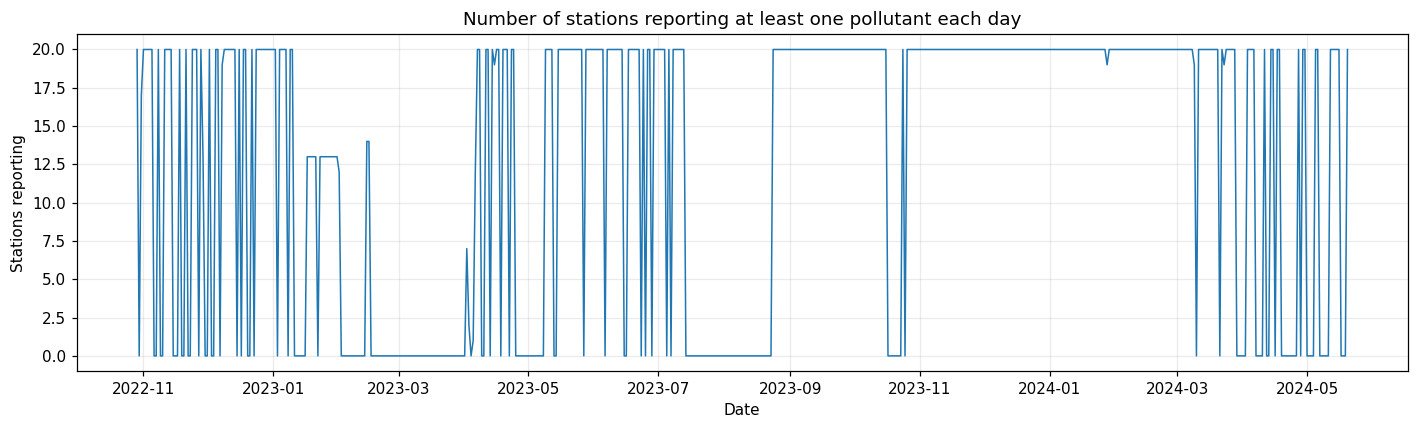

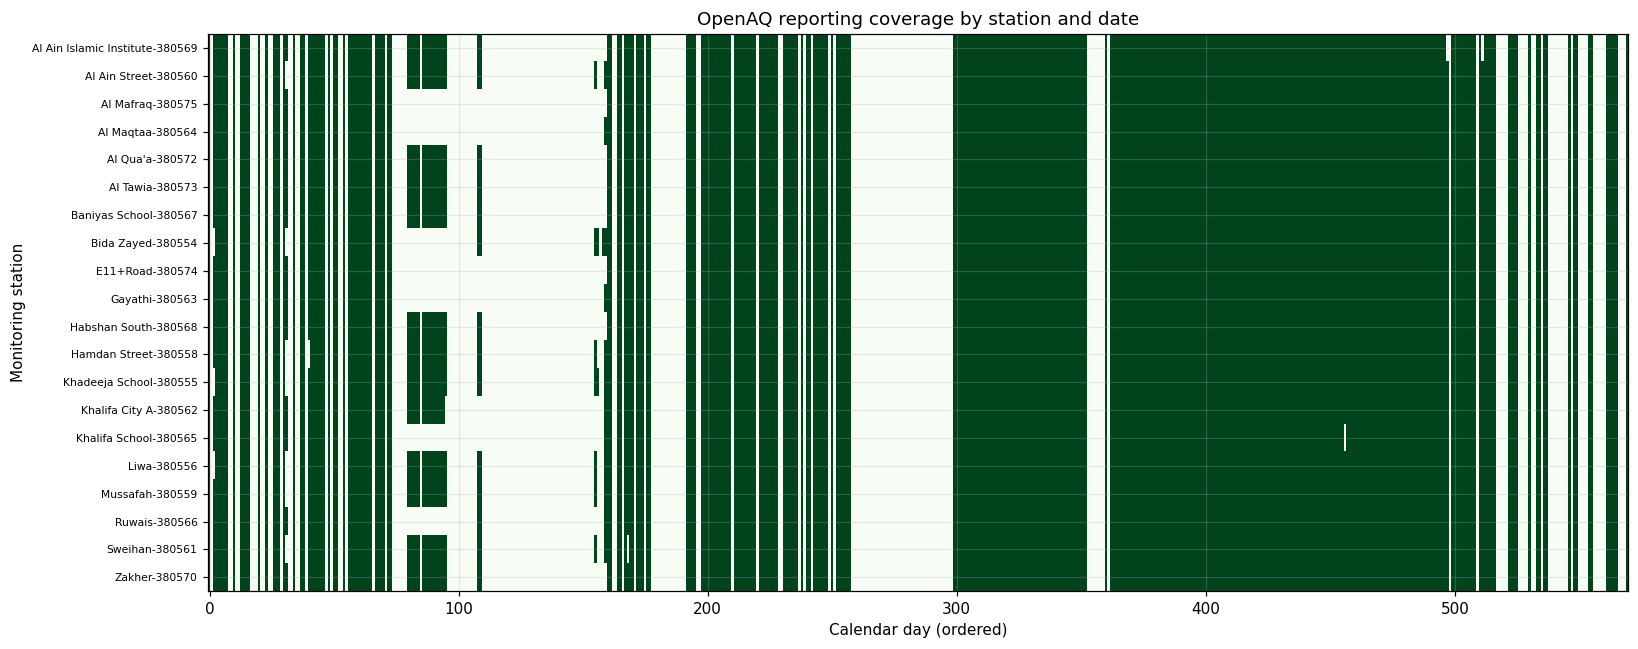

,Available station-days
PM10,7060
NO₂,7104
SO₂,7099
O₃,4976
CO,2475


Distinct dates with any pollution observation: 366


In [11]:
# Observation count by calendar day and pollutant.
daily_coverage = master.groupby("day").agg(
    stations_with_any_record=("any_pollution_record", "sum"),
    station_days_with_any_pollution=("n_pollutants_available", lambda x: int((x > 0).sum())),
).reset_index()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily_coverage.day, daily_coverage.stations_with_any_record, linewidth=1)
ax.set_title("Number of stations reporting at least one pollutant each day")
ax.set_xlabel("Date")
ax.set_ylabel("Stations reporting")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_daily_station_reporting.png", bbox_inches="tight")
plt.show()

# Coverage heatmap: station rows x calendar days columns.
coverage_matrix = master.pivot(index="station_name", columns="day", values="any_pollution_record")
fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(coverage_matrix.fillna(0), aspect="auto", interpolation="nearest", cmap="Greens")
ax.set_title("OpenAQ reporting coverage by station and date")
ax.set_xlabel("Calendar day (ordered)")
ax.set_ylabel("Monitoring station")
ax.set_yticks(range(len(coverage_matrix.index)))
ax.set_yticklabels(coverage_matrix.index, fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_station_date_coverage_heatmap.png", bbox_inches="tight")
plt.show()

availability = pd.DataFrame({
    POLLUTANT_LABELS[p]: master[f"{p}_available"].sum() for p in POLLUTANTS
}, index=["Available station-days"])
display(availability.T)
print("Distinct dates with any pollution observation:", daily.loc[:, "day"].nunique())

**Step 11 result:** The coverage plots show where observations exist and where the station network has gaps. The date range is not equivalent to a continuous daily time series; this matters when interpreting temporal patterns and when constructing sequences for LSTM.

## Step 12 — Reading-support analysis

We compare low, moderate, and higher reading support for every pollutant. This is an essential quality analysis because the daily mean is more representative when more hourly readings contribute to it.

support,Higher (18–24),Low (<12),Moderate (12–17)
pollutant,,,
CO,1247,753,475
NO₂,3562,2186,1356
O₃,2503,1529,944
PM10,3524,2226,1310
SO₂,3557,2183,1359


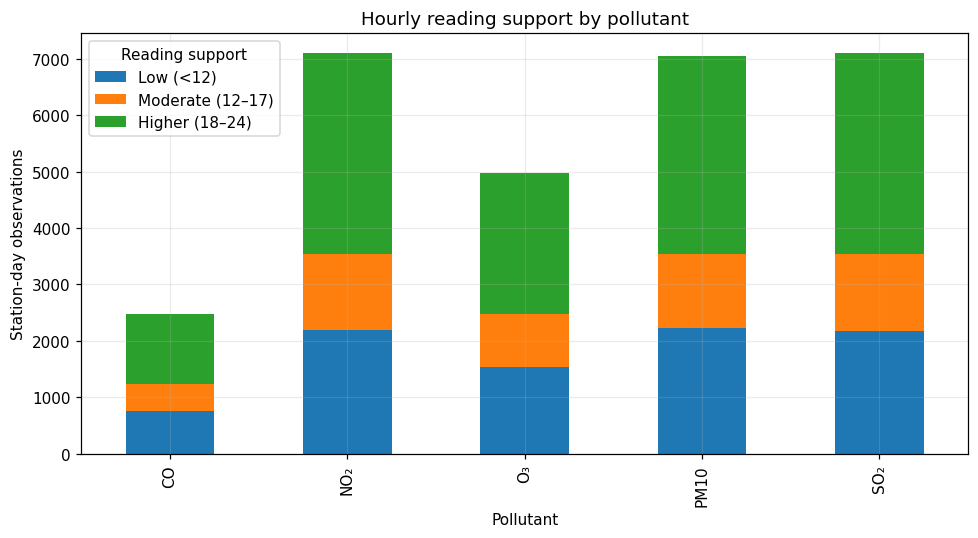

/tmp/ipykernel_1428/1509710030.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_groups, labels=["Low (<12)", "Moderate (12–17)", "Higher (18–24)"], showfliers=False)


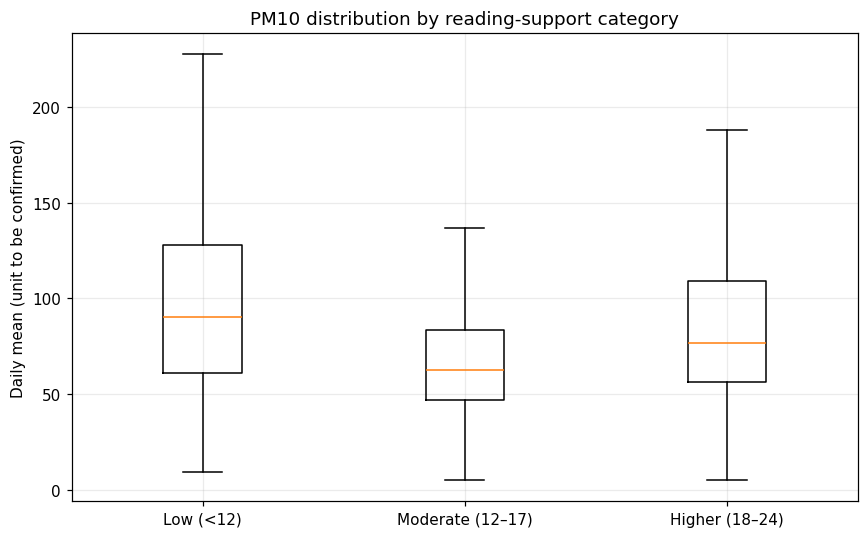

In [12]:
support_long = []
for pollutant in POLLUTANTS:
    r = master[f"{pollutant}_readings"]
    support_long.extend([
        {"pollutant": POLLUTANT_LABELS[pollutant], "support": "Low (<12)", "count": int((r.notna() & r.lt(12)).sum())},
        {"pollutant": POLLUTANT_LABELS[pollutant], "support": "Moderate (12–17)", "count": int(r.between(12, 17).sum())},
        {"pollutant": POLLUTANT_LABELS[pollutant], "support": "Higher (18–24)", "count": int(r.ge(18).sum())},
    ])
support_long = pd.DataFrame(support_long)
support_pivot = support_long.pivot(index="pollutant", columns="support", values="count")
display(support_pivot)

fig, ax = plt.subplots(figsize=(9, 5))
support_pivot[["Low (<12)", "Moderate (12–17)", "Higher (18–24)"]].plot(
    kind="bar", stacked=True, ax=ax
)
ax.set_title("Hourly reading support by pollutant")
ax.set_xlabel("Pollutant")
ax.set_ylabel("Station-day observations")
ax.legend(title="Reading support")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_reading_support_by_pollutant.png", bbox_inches="tight")
plt.show()

# Compare PM10 distributions across support bands as one example.
p = "pm10"
plot_data = master.loc[master[f"{p}_mean"].notna(), [f"{p}_mean", f"{p}_readings"]].copy()
plot_data["support"] = pd.cut(
    plot_data[f"{p}_readings"], bins=[0, 11, 17, 24],
    labels=["Low (<12)", "Moderate (12–17)", "Higher (18–24)"]
)
fig, ax = plt.subplots(figsize=(8, 5))
plot_groups = [plot_data.loc[plot_data.support == label, f"{p}_mean"].dropna() for label in ["Low (<12)", "Moderate (12–17)", "Higher (18–24)"]]
ax.boxplot(plot_groups, labels=["Low (<12)", "Moderate (12–17)", "Higher (18–24)"], showfliers=False)
ax.set_title("PM10 distribution by reading-support category")
ax.set_ylabel("Daily mean (unit to be confirmed)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_pm10_by_reading_support.png", bbox_inches="tight")
plt.show()

**Step 12 result:** This comparison helps determine whether lower-support records behave differently from more complete daily summaries. We will keep all records in the master table, but use the ≥12-reading subset for the main pollutant and weather relationships.

## Step 13 — Descriptive statistics and pollutant distributions

For each pollutant, report three versions: all available records, records with at least 12 readings, and records with at least 18 readings. This makes the support sensitivity transparent.

,pollutant,support_subset,n,mean,median,std,q05,q25,q75,q95,maximum,skewness
0,PM10,All available,7060,94.488,76.869,79.594,34.766,54.904,111.000,203.791,2750.833,10.042
1,PM10,12+ readings,4834,87.501,72.354,69.354,34.896,52.908,102.424,177.700,1913.235,8.417
2,PM10,18+ readings,3524,92.039,76.689,67.329,37.594,56.337,109.010,183.215,1129.045,5.781
3,NO₂,All available,7104,25.805,19.084,23.680,4.118,10.020,35.806,65.822,352.740,4.348
4,NO₂,12+ readings,4918,27.197,21.412,19.901,5.568,12.008,38.221,66.348,150.528,1.280
5,NO₂,18+ readings,3562,28.019,22.335,19.759,5.569,12.301,40.362,66.752,135.415,0.993
6,SO₂,All available,7099,12.745,10.905,10.455,4.250,7.741,15.467,26.675,373.276,15.016
7,SO₂,12+ readings,4916,12.546,10.981,9.688,4.693,7.890,15.289,24.944,373.276,16.010
8,SO₂,18+ readings,3557,12.518,10.697,10.531,4.512,7.813,15.421,24.927,373.276,16.824
9,O₃,All available,4976,81.497,78.859,29.210,38.768,62.263,96.491,137.356,224.410,0.686


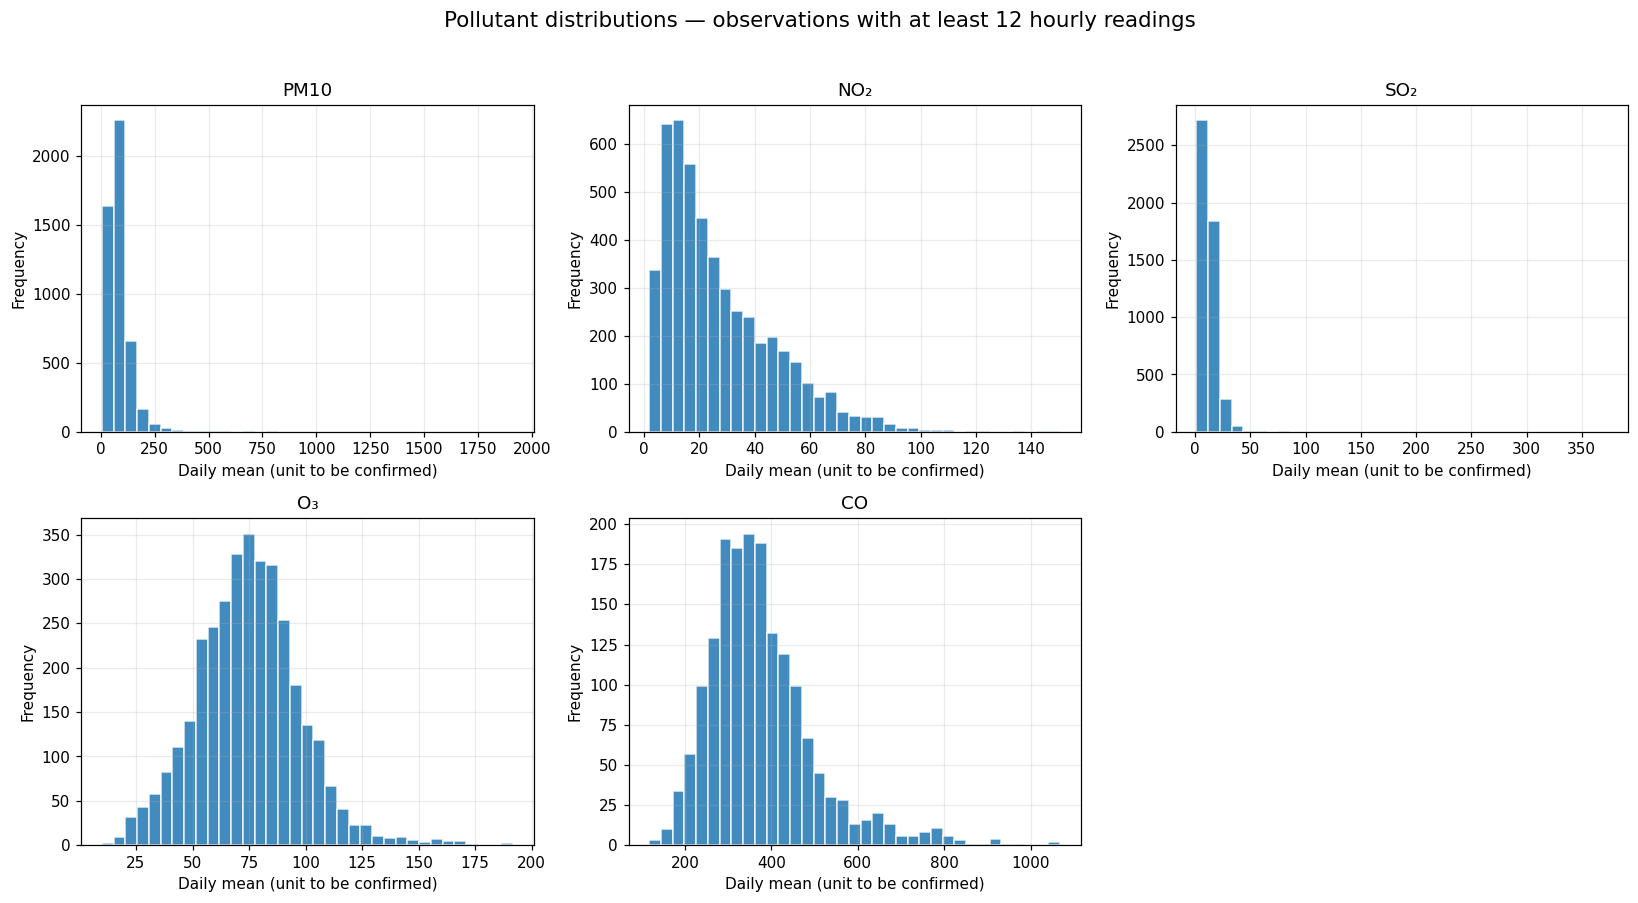

In [13]:
descriptive_rows = []
for pollutant in POLLUTANTS:
    value_col = f"{pollutant}_mean"
    readings_col = f"{pollutant}_readings"
    for label, mask in [
        ("All available", master[value_col].notna()),
        ("12+ readings", master[readings_col].ge(12) & master[value_col].notna()),
        ("18+ readings", master[readings_col].ge(18) & master[value_col].notna()),
    ]:
        values = master.loc[mask, value_col].dropna()
        descriptive_rows.append({
            "pollutant": POLLUTANT_LABELS[pollutant],
            "support_subset": label,
            "n": len(values),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "q05": values.quantile(0.05),
            "q25": values.quantile(0.25),
            "q75": values.quantile(0.75),
            "q95": values.quantile(0.95),
            "maximum": values.max(),
            "skewness": values.skew(),
        })
descriptive_stats = pd.DataFrame(descriptive_rows)
display(descriptive_stats.round(3))
descriptive_stats.to_csv(TABLE_DIR / "pollutant_descriptive_statistics_support_sensitivity.csv", index=False)

# Five-panel histogram using the main >=12-reading subset.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, pollutant in zip(axes.flat, POLLUTANTS):
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN)[f"{pollutant}_mean"].dropna()
    ax.hist(data, bins=35, edgecolor="white", alpha=0.85)
    ax.set_title(POLLUTANT_LABELS[pollutant])
    ax.set_xlabel("Daily mean (unit to be confirmed)")
    ax.set_ylabel("Frequency")
axes.flat[-1].axis("off")
fig.suptitle("Pollutant distributions — observations with at least 12 hourly readings", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_five_pollutant_distributions_12plus.png", bbox_inches="tight")
plt.show()

**Step 13 result:** Skewness and upper quantiles help describe the long-tailed nature of pollution data. Do not remove extreme values solely because they are far from the median; they may represent meaningful events or data-quality problems that require investigation.

## Step 14 — Station-level pollutant comparisons

We compare station medians using only observations with at least 12 readings. Medians are used because extreme values can strongly affect means.

,station_id,station_name,observations,median,mean,q95,maximum,pollutant
75,369959,Al Ain Street-380560,246,399.782609,416.872590,653.524845,1068.333333,CO
79,369971,Al Qua'a-380572,243,381.304348,381.632251,487.750000,566.190476,CO
74,369957,Hamdan Street-380558,244,380.910931,396.493621,596.482372,761.304348,CO
77,369963,Al Maqtaa-380564,245,370.454545,414.751818,703.014493,1047.916667,CO
78,369965,Ruwais-380566,249,335.416667,383.761848,746.583333,946.666667,CO
...,...,...,...,...,...,...,...,...
46,369960,Sweihan-380561,247,9.030833,9.703939,16.487696,42.425385,SO₂
45,369959,Al Ain Street-380560,246,8.598167,8.959710,14.557560,25.346923,SO₂
52,369966,Baniyas School-380567,247,8.067143,8.105169,13.567654,19.273684,SO₂
56,369971,Al Qua'a-380572,244,7.546801,8.404154,14.048771,21.461250,SO₂


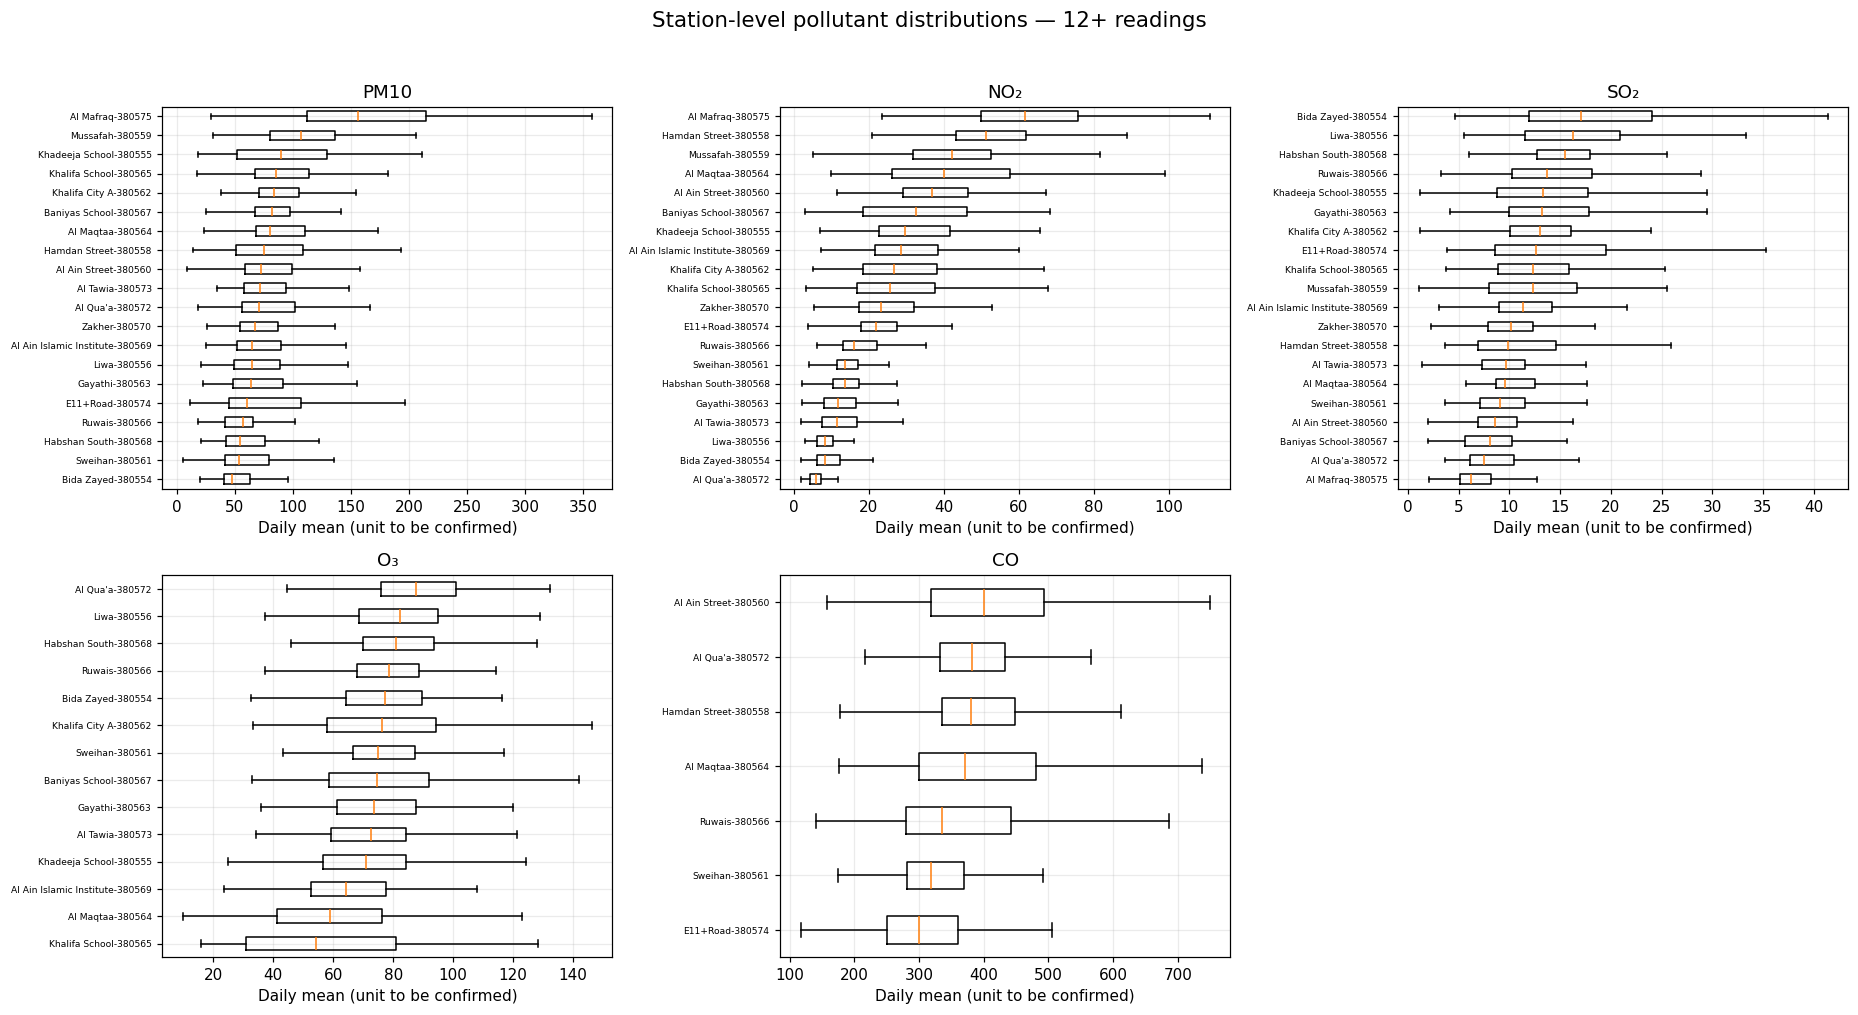

In [14]:
station_rows = []
for pollutant in POLLUTANTS:
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN)
    summary = data.groupby(["station_id", "station_name"]).agg(
        observations=(f"{pollutant}_mean", "count"),
        median=(f"{pollutant}_mean", "median"),
        mean=(f"{pollutant}_mean", "mean"),
        q95=(f"{pollutant}_mean", lambda x: x.quantile(0.95)),
        maximum=(f"{pollutant}_mean", "max"),
    ).reset_index()
    summary["pollutant"] = POLLUTANT_LABELS[pollutant]
    station_rows.append(summary)
station_summary = pd.concat(station_rows, ignore_index=True)
display(station_summary.sort_values(["pollutant", "median"], ascending=[True, False]))
station_summary.to_csv(TABLE_DIR / "station_pollutant_summary_12plus.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, pollutant in zip(axes.flat, POLLUTANTS):
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN)
    order = data.groupby("station_name")[f"{pollutant}_mean"].median().sort_values().index
    groups = [data.loc[data.station_name == station, f"{pollutant}_mean"].dropna() for station in order]
    ax.boxplot(groups, showfliers=False, vert=False)
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels(order, fontsize=6)
    ax.set_title(POLLUTANT_LABELS[pollutant])
    ax.set_xlabel("Daily mean (unit to be confirmed)")
axes.flat[-1].axis("off")
fig.suptitle("Station-level pollutant distributions — 12+ readings", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_station_pollutant_boxplots.png", bbox_inches="tight")
plt.show()

**Step 14 result:** Station medians and upper quantiles reveal persistent differences between locations. These are descriptive comparisons; they do not establish the source or cause of the differences.

## Step 15 — Geographic station view

We plot station coordinates and colour each station by its median PM10 concentration (12+ readings). This is a coordinate scatter plot, not a detailed road or administrative map.

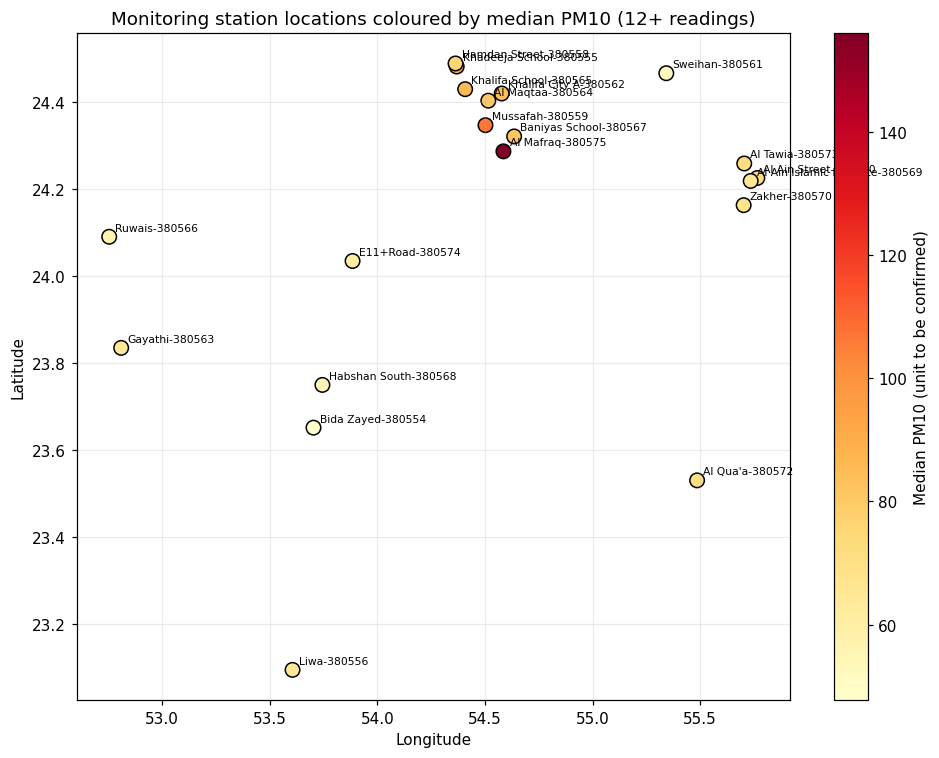

In [15]:
pm10_station = station_summary.loc[station_summary.pollutant == "PM10"].merge(
    stations[["station_id", "lat", "lon"]], on="station_id", how="left"
)
fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(
    pm10_station.lon, pm10_station.lat,
    c=pm10_station["median"], s=90, cmap="YlOrRd", edgecolor="black"
)
for _, row in pm10_station.iterrows():
    ax.annotate(row.station_name, (row.lon, row.lat), xytext=(4, 4),
                textcoords="offset points", fontsize=7)
fig.colorbar(points, ax=ax, label="Median PM10 (unit to be confirmed)")
ax.set_title("Monitoring station locations coloured by median PM10 (12+ readings)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_station_coordinate_map_pm10.png", bbox_inches="tight")
plt.show()

**Step 15 result:** The spatial plot helps identify geographic clusters for further investigation. Because no basemap is included, use it as a station-coordinate overview rather than a precise geographic boundary map.

## Step 16 — Temporal patterns and monthly behaviour

We summarize station-day medians by month for each pollutant, using the ≥12-reading subset. This avoids allowing a single station with many records to dominate the monthly summary.

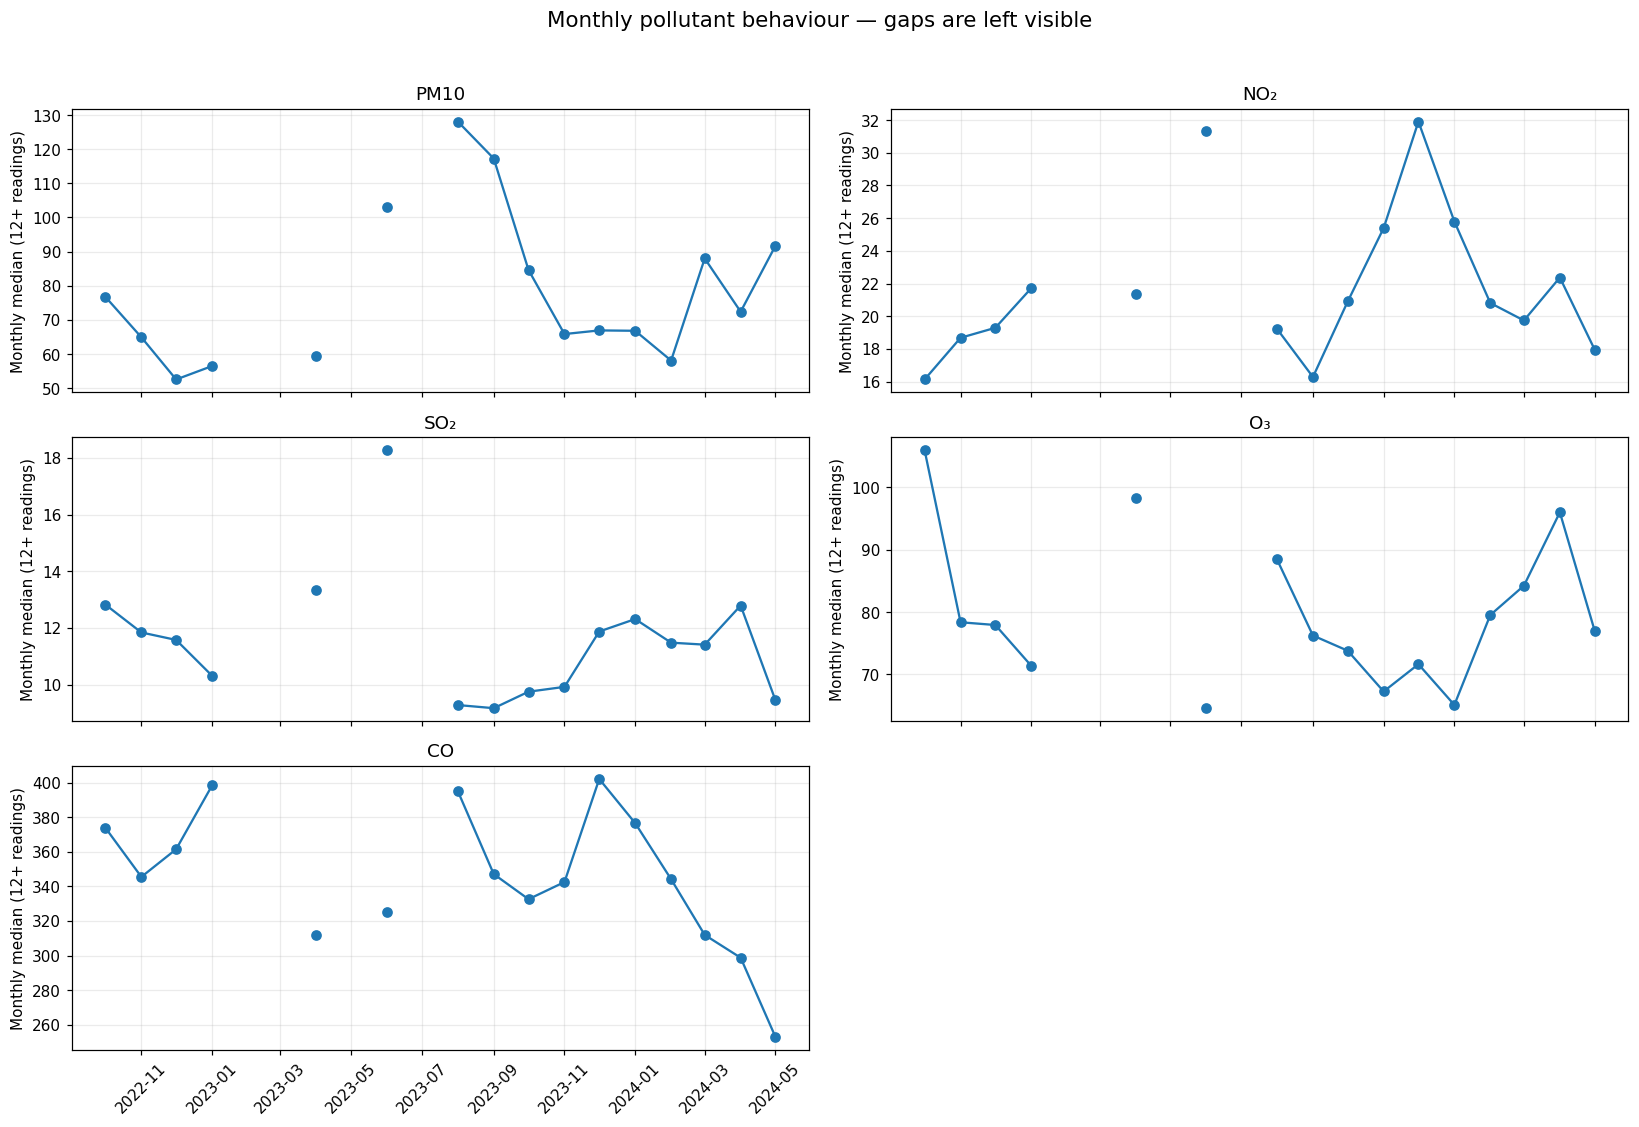

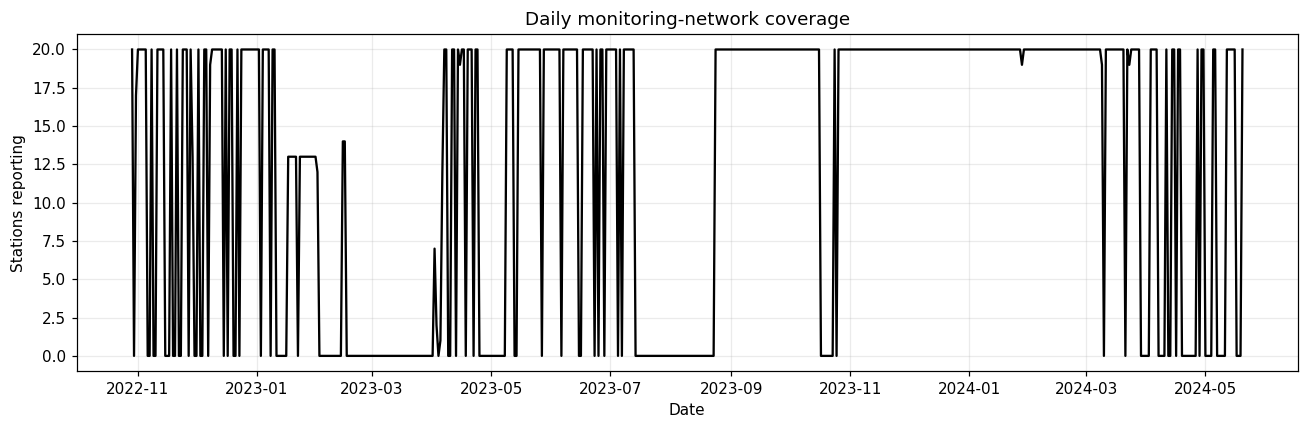

In [16]:
monthly_rows = []
all_months = pd.date_range(master.month_start.min(), master.month_start.max(), freq="MS")

for pollutant in POLLUTANTS:
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN).copy()
    monthly = data.groupby("month_start").agg(
        network_station_day_median=(f"{pollutant}_mean", "median"),
        network_station_day_mean=(f"{pollutant}_mean", "mean"),
        station_days=(f"{pollutant}_mean", "count"),
        stations_reporting=("station_id", "nunique"),
    ).reindex(all_months)
    monthly.index.name = "month_start"
    monthly = monthly.reset_index()
    monthly["pollutant"] = POLLUTANT_LABELS[pollutant]
    monthly_rows.append(monthly)

monthly_summary = pd.concat(monthly_rows, ignore_index=True)
monthly_summary.to_csv(TABLE_DIR / "monthly_pollutant_summary_12plus.csv", index=False)

fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
for ax, pollutant in zip(axes.flat, POLLUTANTS):
    data = monthly_summary.loc[monthly_summary.pollutant == POLLUTANT_LABELS[pollutant]]
    # NaN months remain in the series, so matplotlib does not draw a line across a gap.
    ax.plot(data.month_start, data.network_station_day_median, marker="o", linewidth=1.5)
    ax.set_title(POLLUTANT_LABELS[pollutant])
    ax.set_ylabel("Monthly median (12+ readings)")
    ax.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
fig.suptitle("Monthly pollutant behaviour — gaps are left visible", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_monthly_pollutant_trends.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_coverage.day, daily_coverage.stations_with_any_record, color="black")
ax.set_title("Daily monitoring-network coverage")
ax.set_xlabel("Date")
ax.set_ylabel("Stations reporting")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_network_reporting_over_time.png", bbox_inches="tight")
plt.show()


**Step 16 result:** The monthly plots show broad temporal patterns, but the sampling regime changes over the study period. Interpret early months with lower hourly support separately from the better-supported later period.

## Step 17 — Pooled pollutant correlations

We calculate Spearman correlations using each pollutant's observations with at least 12 readings. Pairwise sample sizes are reported because O3 and especially CO have lower coverage.

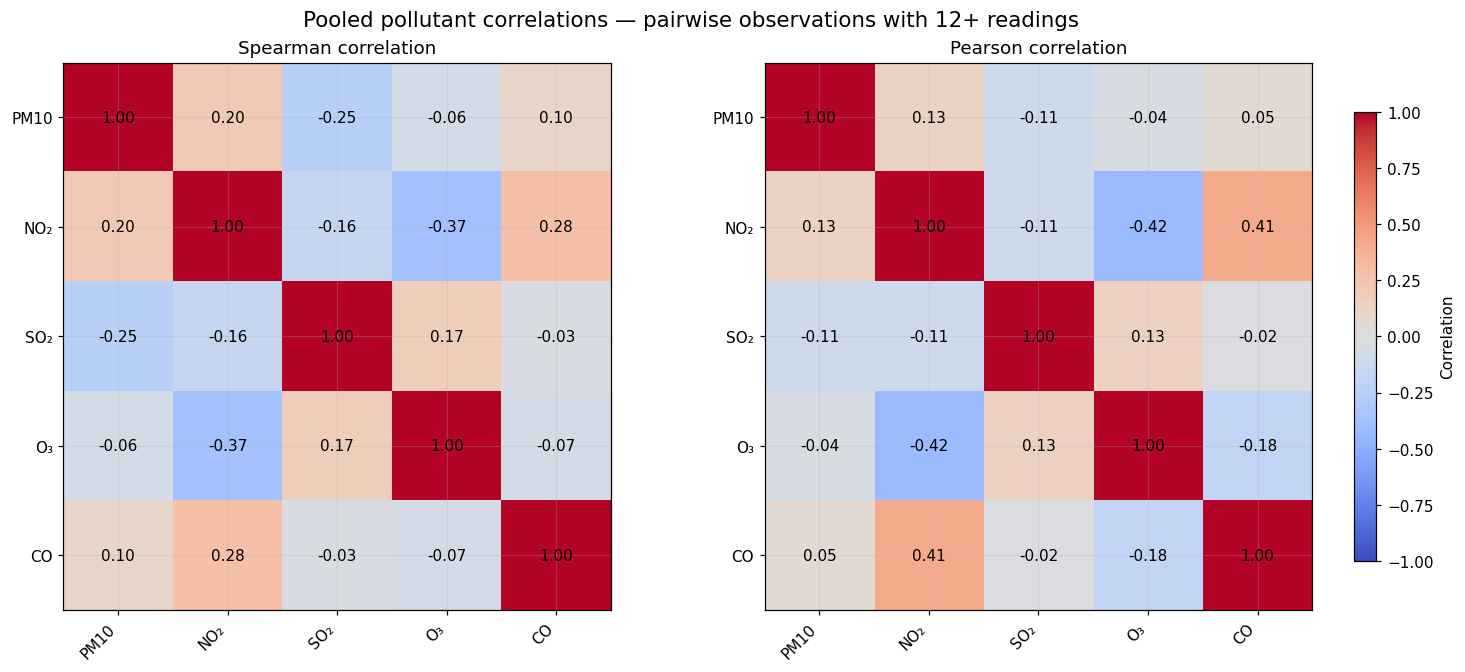

,pm10_mean,no2_mean,so2_mean,o3_mean,co_mean
pm10_mean,1.000,0.200,-0.248,-0.063,0.101
no2_mean,0.200,1.000,-0.156,-0.368,0.275
so2_mean,-0.248,-0.156,1.000,0.174,-0.032
o3_mean,-0.063,-0.368,0.174,1.000,-0.066
co_mean,0.101,0.275,-0.032,-0.066,1.000


,pm10_mean,no2_mean,so2_mean,o3_mean,co_mean
pm10_mean,4902.0,4902.0,4902.0,3431.0,1715.0
no2_mean,4902.0,4936.0,4936.0,3456.0,1729.0
so2_mean,4902.0,4936.0,4936.0,3456.0,1729.0
o3_mean,3431.0,3456.0,3456.0,3456.0,989.0
co_mean,1715.0,1729.0,1729.0,989.0,1729.0


In [17]:
pollutant_mean_columns = [f"{p}_mean" for p in POLLUTANTS]
reliable_any = master[[f"{p}_readings" for p in POLLUTANTS]].ge(MIN_READINGS_MAIN).any(axis=1)
reliable_view = master.loc[reliable_any].copy()

spearman_corr = reliable_view[pollutant_mean_columns].corr(method="spearman")
pearson_corr = reliable_view[pollutant_mean_columns].corr(method="pearson")

pair_counts = pd.DataFrame(index=pollutant_mean_columns, columns=pollutant_mean_columns, dtype=int)
for a in pollutant_mean_columns:
    for b in pollutant_mean_columns:
        pair_counts.loc[a, b] = int((reliable_view[a].notna() & reliable_view[b].notna()).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
image = None
for ax, matrix, title in [
    (axes[0], spearman_corr, "Spearman correlation"),
    (axes[1], pearson_corr, "Pearson correlation"),
]:
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels([POLLUTANT_LABELS[p] for p in POLLUTANTS], rotation=45, ha="right")
    ax.set_yticklabels([POLLUTANT_LABELS[p] for p in POLLUTANTS])
    ax.set_title(title)
    for i in range(5):
        for j in range(5):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}" if pd.notna(value) else "NA", ha="center", va="center")
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.82, pad=0.03, label="Correlation")
fig.suptitle("Pooled pollutant correlations — pairwise observations with 12+ readings", fontsize=14)
fig.savefig(FIGURE_DIR / "10_pooled_pollutant_correlations.png", bbox_inches="tight")
plt.show()

display(spearman_corr.round(3))
display(pair_counts)
spearman_corr.to_csv(TABLE_DIR / "pooled_pollutant_spearman_12plus.csv")
pearson_corr.to_csv(TABLE_DIR / "pooled_pollutant_pearson_12plus.csv")
pair_counts.to_csv(TABLE_DIR / "pollutant_correlation_pair_counts_12plus.csv")


**Step 17 result:** Pooled correlations are useful first summaries, but they can mix station differences and seasonal changes. The next step checks whether relationships look similar within individual stations.

## Step 18 — Within-station pollutant correlations

For each pollutant pair, calculate Spearman correlation separately within each station (using ≥12-reading observations). Then summarize the median, range, number of stations, and number of paired observations. This helps identify pooled relationships driven by station-to-station differences.

In [18]:
pair_rows = []
for i, pollutant_a in enumerate(POLLUTANTS):
    for pollutant_b in POLLUTANTS[i + 1:]:
        station_values = []
        for station_id, group in master.groupby("station_id"):
            mask = (
                group[f"{pollutant_a}_readings"].ge(MIN_READINGS_MAIN) &
                group[f"{pollutant_b}_readings"].ge(MIN_READINGS_MAIN) &
                group[f"{pollutant_a}_mean"].notna() &
                group[f"{pollutant_b}_mean"].notna()
            )
            subset = group.loc[mask]
            if len(subset) >= 20:
                corr = subset[f"{pollutant_a}_mean"].corr(
                    subset[f"{pollutant_b}_mean"], method="spearman"
                )
                if pd.notna(corr):
                    station_values.append({
                        "station_id": station_id,
                        "station_name": subset.station_name.iloc[0],
                        "rho": corr,
                        "n": len(subset),
                    })
        values = pd.DataFrame(station_values)
        pair_rows.append({
            "pollutant_a": POLLUTANT_LABELS[pollutant_a],
            "pollutant_b": POLLUTANT_LABELS[pollutant_b],
            "stations_with_n_ge_20": len(values),
            "median_within_station_rho": values.rho.median() if len(values) else np.nan,
            "minimum_station_rho": values.rho.min() if len(values) else np.nan,
            "maximum_station_rho": values.rho.max() if len(values) else np.nan,
        })
within_station_summary = pd.DataFrame(pair_rows)
display(within_station_summary.round(3))
within_station_summary.to_csv(TABLE_DIR / "within_station_pollutant_correlations.csv", index=False)

,pollutant_a,pollutant_b,stations_with_n_ge_20,median_within_station_rho,minimum_station_rho,maximum_station_rho
0,PM10,NO₂,20,-0.145,-0.422,0.185
1,PM10,SO₂,20,-0.113,-0.393,0.138
2,PM10,O₃,14,0.010,-0.233,0.339
3,PM10,CO,7,-0.044,-0.136,0.192
4,NO₂,SO₂,20,0.080,-0.424,0.572
5,NO₂,O₃,14,-0.283,-0.653,0.287
6,NO₂,CO,7,0.453,0.087,0.759
7,SO₂,O₃,14,0.199,-0.182,0.513
8,SO₂,CO,7,0.118,-0.178,0.294
9,O₃,CO,4,0.059,-0.559,0.209


**Step 18 result:** If pooled and within-station correlations differ, the pooled relationship may partly reflect differences between stations. Report both rather than relying on one pooled heatmap.

## Step 19 — Weather distributions and hourly-to-daily checks

The hourly file is used for two purposes: validate the daily aggregates and describe the weather profile over a day. It cannot identify the exact weather at the hour of a pollution spike because the OpenAQ pollution input is daily, not hourly.

,count,mean,std,min,25%,50%,75%,max
temperature_mean,11400.0,27.484,5.901,15.167,22.403,26.627,33.130,40.238
humidity_mean,11400.0,53.353,14.301,12.917,42.958,55.542,64.167,88.125
dew_point_mean,11400.0,15.684,5.295,-2.146,12.171,15.346,19.037,28.975
rainfall_total,11400.0,0.340,3.399,0.000,0.000,0.000,0.000,107.300
pressure_mean,11400.0,1011.038,6.917,994.929,1006.688,1012.908,1016.559,1024.692
wind_speed_mean,11400.0,13.066,3.892,4.188,10.353,12.296,15.062,33.033
wind_speed_max,11400.0,21.711,5.468,8.100,18.000,21.400,24.900,51.500
cloud_cover_mean,11400.0,24.447,25.542,0.000,2.958,15.708,38.458,99.667
wind_direction_mean,11400.0,192.795,123.302,0.009,68.421,192.994,312.136,359.935


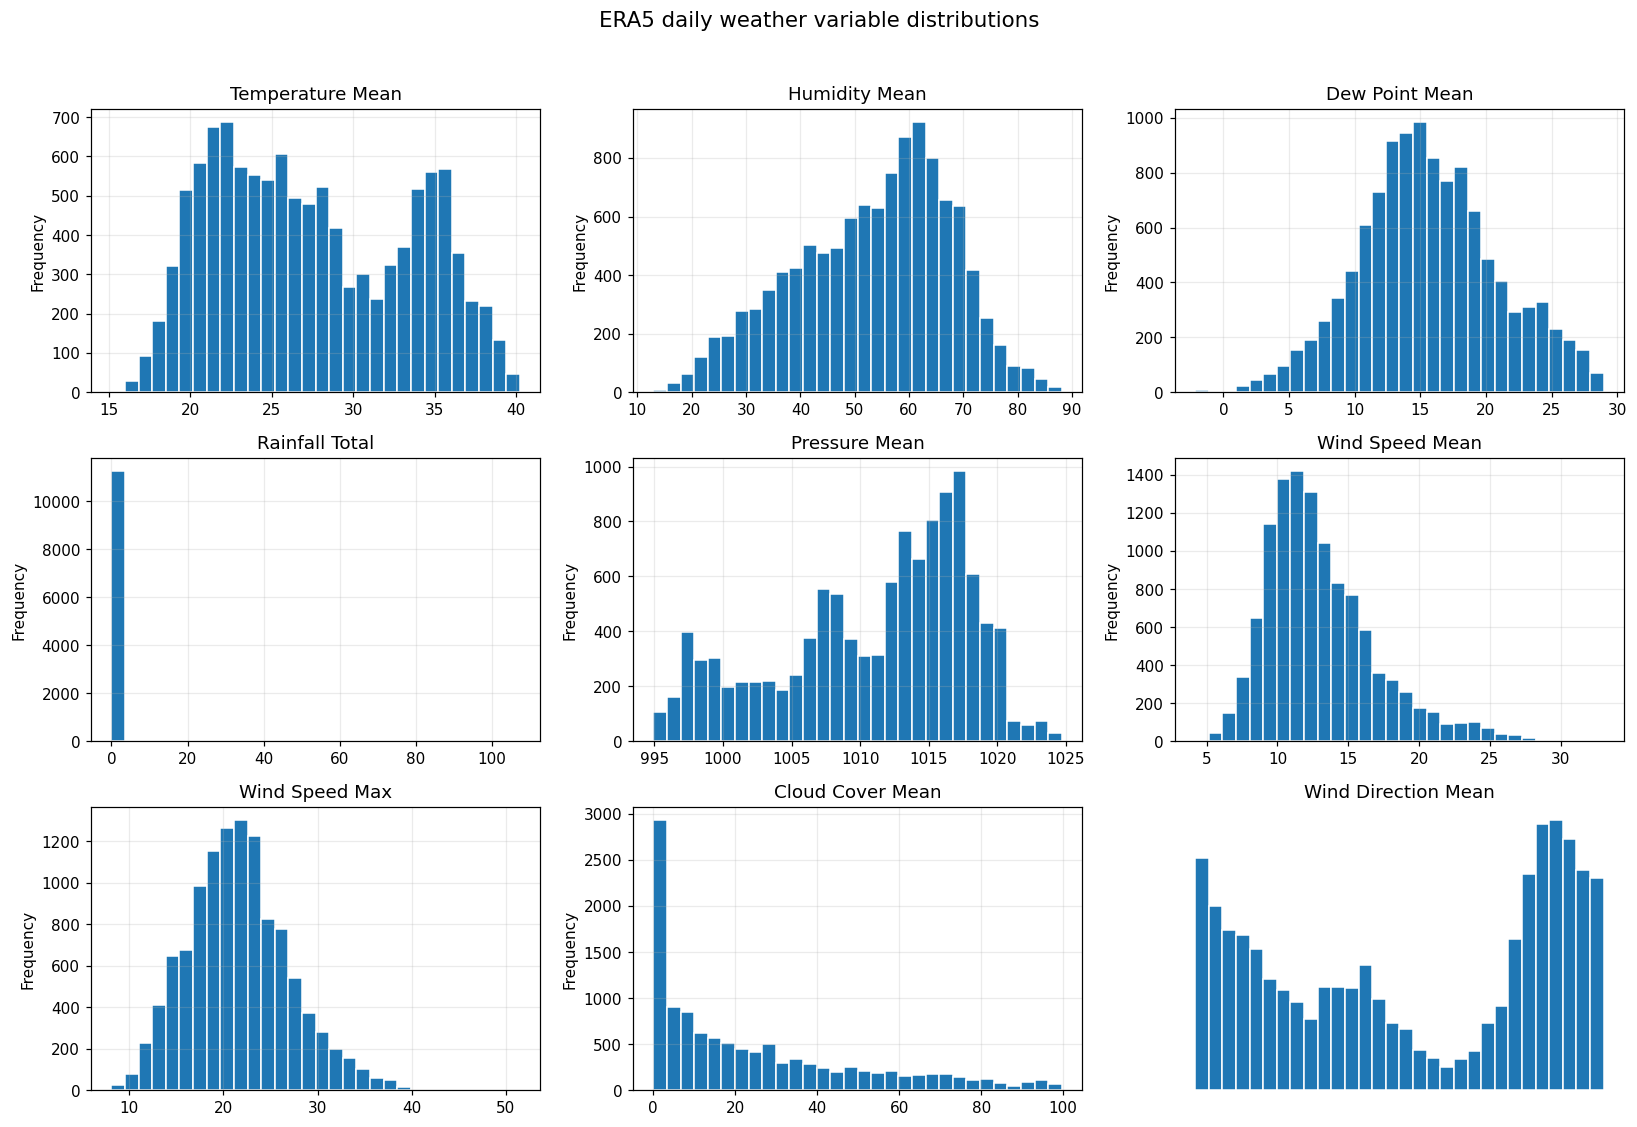

Weather station-days after hourly aggregation: 11400
Unique hourly grid cells: 11
All source weather variables were requested in Asia/Dubai timezone by the downloader.


In [19]:
weather_variables = [
    "temperature_mean", "humidity_mean", "dew_point_mean", "rainfall_total",
    "pressure_mean", "wind_speed_mean", "wind_speed_max", "cloud_cover_mean",
    "wind_direction_mean"
]
weather_summary = master[weather_variables].describe().T
weather_summary.to_csv(TABLE_DIR / "weather_descriptive_statistics.csv")
display(weather_summary.round(3))

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, variable in zip(axes.flat, weather_variables):
    values = master[variable].dropna()
    ax.hist(values, bins=30, edgecolor="white")
    ax.set_title(variable.replace("_", " ").title())
    ax.set_ylabel("Frequency")
axes.flat[-1].axis("off")
fig.suptitle("ERA5 daily weather variable distributions", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_weather_variable_distributions.png", bbox_inches="tight")
plt.show()

# The daily file was rebuilt from the hourly data above. Display whether the daily table matches.
print("Weather station-days after hourly aggregation:", len(weather_from_hourly))
print("Unique hourly grid cells:", hourly[["grid_latitude", "grid_longitude"]].drop_duplicates().shape[0])
print("All source weather variables were requested in Asia/Dubai timezone by the downloader.")

**Step 19 result:** Weather summaries are validated using the hourly records. The grid-sharing table from Step 8 must be considered when interpreting station-level weather relationships.

## Step 20 — Pollutant–weather relationships

We calculate pooled Spearman correlations and a station-month-adjusted sensitivity version. For the adjusted version, we subtract each station's monthly median from both variables before calculating Spearman correlation. This reduces some station and seasonal level effects, but it is still a descriptive adjustment, not a causal model.

,pollutant,weather_variable,n_pairs,pooled_spearman,station_month_adjusted_spearman
0,PM10,temperature_mean,4834,0.455,0.203
1,PM10,humidity_mean,4834,-0.162,-0.090
2,PM10,dew_point_mean,4834,0.325,0.055
3,PM10,rainfall_total,4834,-0.094,-0.028
4,PM10,pressure_mean,4834,-0.435,-0.198
5,PM10,wind_speed_mean,4834,0.084,0.162
6,PM10,wind_speed_max,4834,0.208,0.179
7,PM10,cloud_cover_mean,4834,-0.077,0.079
8,NO₂,temperature_mean,4918,-0.063,-0.101
9,NO₂,humidity_mean,4918,0.086,-0.182


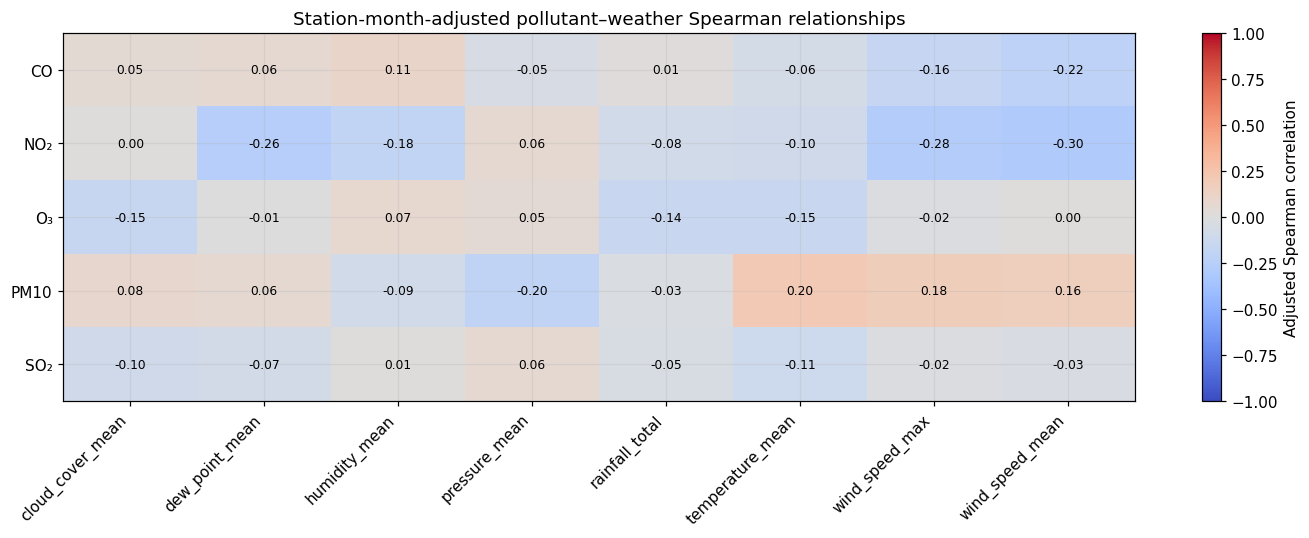

In [20]:
weather_for_corr = [
    "temperature_mean", "humidity_mean", "dew_point_mean", "rainfall_total",
    "pressure_mean", "wind_speed_mean", "wind_speed_max", "cloud_cover_mean"
]

weather_corr_rows = []
for pollutant in POLLUTANTS:
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN).copy()
    data["station_month"] = data.station_id.astype(str) + "_" + data.month_start.astype(str)
    for weather_variable in weather_for_corr:
        pair = data[[f"{pollutant}_mean", weather_variable, "station_month"]].dropna()
        pooled_rho = pair[f"{pollutant}_mean"].corr(pair[weather_variable], method="spearman")
        pair["pollutant_residual"] = pair[f"{pollutant}_mean"] - pair.groupby("station_month")[f"{pollutant}_mean"].transform("median")
        pair["weather_residual"] = pair[weather_variable] - pair.groupby("station_month")[weather_variable].transform("median")
        adjusted_rho = pair.pollutant_residual.corr(pair.weather_residual, method="spearman")
        weather_corr_rows.append({
            "pollutant": POLLUTANT_LABELS[pollutant],
            "weather_variable": weather_variable,
            "n_pairs": len(pair),
            "pooled_spearman": pooled_rho,
            "station_month_adjusted_spearman": adjusted_rho,
        })
weather_correlations = pd.DataFrame(weather_corr_rows)
display(weather_correlations.round(3))
weather_correlations.to_csv(TABLE_DIR / "pollutant_weather_correlations_12plus.csv", index=False)

heatmap = weather_correlations.pivot(
    index="pollutant", columns="weather_variable", values="station_month_adjusted_spearman"
)
fig, ax = plt.subplots(figsize=(13, 5))
image = ax.imshow(heatmap, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_yticks(range(len(heatmap.index))); ax.set_yticklabels(heatmap.index)
ax.set_xticks(range(len(heatmap.columns))); ax.set_xticklabels(heatmap.columns, rotation=45, ha="right")
ax.set_title("Station-month-adjusted pollutant–weather Spearman relationships")
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        value = heatmap.iloc[i, j]
        ax.text(j, i, f"{value:.2f}" if pd.notna(value) else "NA", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Adjusted Spearman correlation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_pollutant_weather_adjusted_correlations.png", bbox_inches="tight")
plt.show()

**Step 20 result:** Compare the pooled and adjusted columns. If a relationship becomes much weaker after station-month adjustment, it may largely reflect seasonal or station-level differences. These are associations, not causal effects.

## Step 21 — Weather scatterplots for selected pollutant pairs

These plots provide visual checks for the correlations. To keep them readable, each pollutant uses its own valid ≥12-reading observations. The full data remains available in the master table.

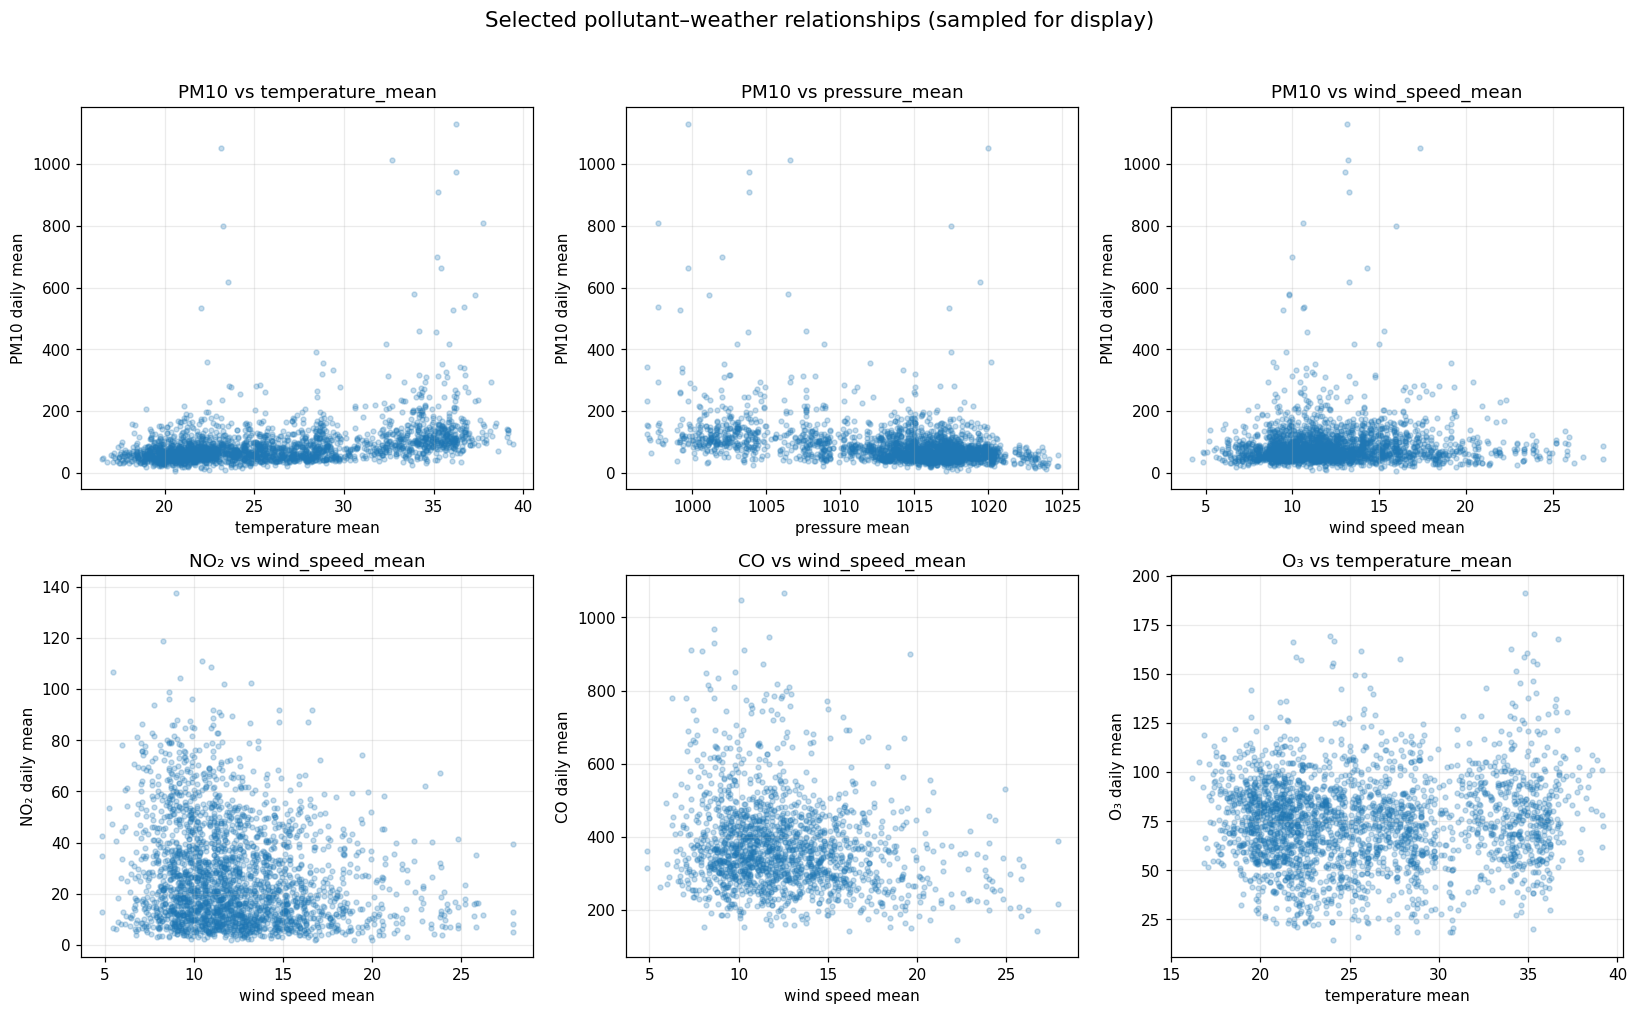

In [21]:
scatter_pairs = [
    ("pm10", "temperature_mean"), ("pm10", "pressure_mean"),
    ("pm10", "wind_speed_mean"), ("no2", "wind_speed_mean"),
    ("co", "wind_speed_mean"), ("o3", "temperature_mean"),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (pollutant, weather_variable) in zip(axes.flat, scatter_pairs):
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN)
    data = data[[f"{pollutant}_mean", weather_variable]].dropna()
    if len(data) > 2500:
        data = data.sample(2500, random_state=42)
    ax.scatter(data[weather_variable], data[f"{pollutant}_mean"], alpha=0.25, s=10)
    ax.set_xlabel(weather_variable.replace("_", " "))
    ax.set_ylabel(POLLUTANT_LABELS[pollutant] + " daily mean")
    ax.set_title(f"{POLLUTANT_LABELS[pollutant]} vs {weather_variable}")
fig.suptitle("Selected pollutant–weather relationships (sampled for display)", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "13_selected_pollutant_weather_scatterplots.png", bbox_inches="tight")
plt.show()

**Step 21 result:** Scatterplots reveal non-linear patterns, clusters, and influential points that a single correlation coefficient cannot describe. Treat them as exploratory evidence.

## Step 22 — Wind-direction analysis

Wind direction is circular. We use the daily circular mean direction to assign broad wind sectors. The plots show pollutant distributions by sector for the ≥12-reading subset. Small sector sample sizes must be reported.

,wind_sector,observations,median,mean,pollutant
0,N,1154,68.043561,83.348376,PM10
1,NE,810,73.298007,83.999020,PM10
2,E,450,70.348739,86.842863,PM10
3,SE,427,84.428571,103.895291,PM10
4,S,263,90.176471,104.712315,PM10
5,SW,120,84.989011,99.363892,PM10
6,W,375,79.153846,92.768232,PM10
7,NW,1235,68.625000,81.831245,PM10
8,N,1186,20.832115,26.148938,NO₂
9,NE,820,22.976186,29.227914,NO₂


/tmp/ipykernel_1428/3252498413.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=sector_labels, showfliers=False)
/tmp/ipykernel_1428/3252498413.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=sector_labels, showfliers=False)
/tmp/ipykernel_1428/3252498413.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=sector_labels, showfliers=False)
/tmp/ipykernel_1428/3252498413.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be droppe

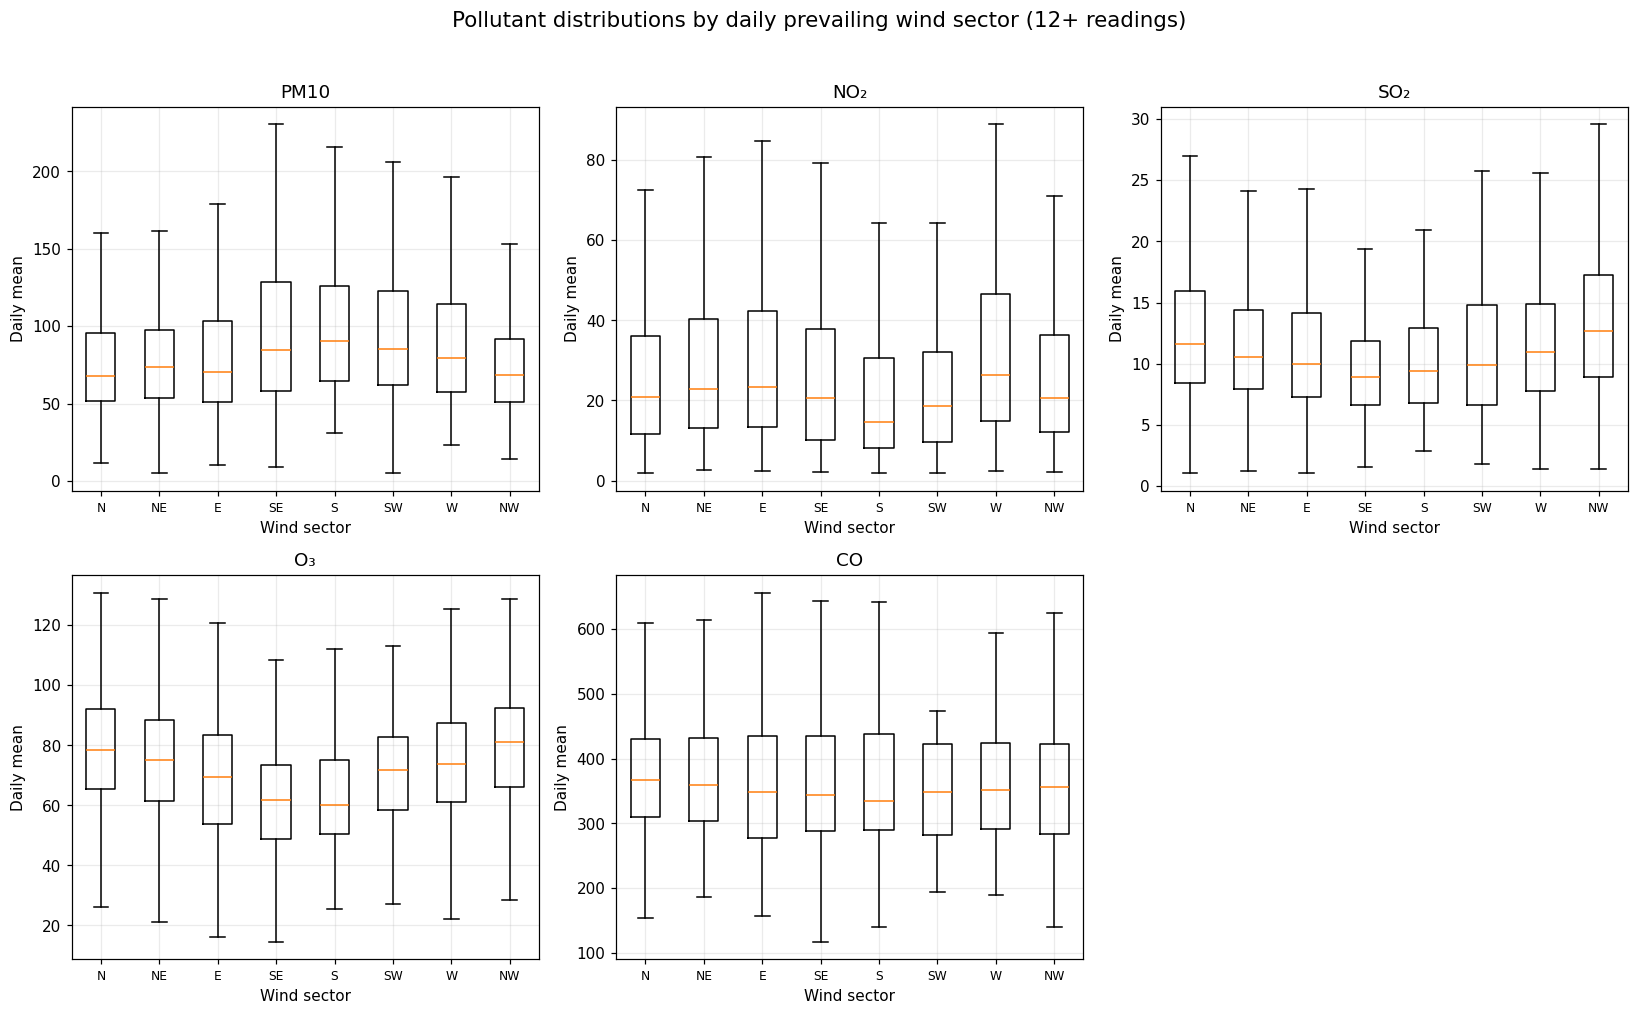

In [22]:
wind_rows = []
for pollutant in POLLUTANTS:
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN)
    data = data.dropna(subset=["wind_sector", f"{pollutant}_mean"])
    grouped = data.groupby("wind_sector", observed=False).agg(
        observations=(f"{pollutant}_mean", "count"),
        median=(f"{pollutant}_mean", "median"),
        mean=(f"{pollutant}_mean", "mean"),
    ).reset_index()
    grouped["pollutant"] = POLLUTANT_LABELS[pollutant]
    wind_rows.append(grouped)
wind_sector_summary = pd.concat(wind_rows, ignore_index=True)
wind_sector_summary.to_csv(TABLE_DIR / "pollutant_by_wind_sector_12plus.csv", index=False)
display(wind_sector_summary)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, pollutant in zip(axes.flat, POLLUTANTS):
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN)
    data = data.dropna(subset=["wind_sector", f"{pollutant}_mean"])
    groups = [data.loc[data.wind_sector == sector, f"{pollutant}_mean"].dropna()
              for sector in sector_labels]
    ax.boxplot(groups, labels=sector_labels, showfliers=False)
    ax.set_title(POLLUTANT_LABELS[pollutant])
    ax.set_xlabel("Wind sector")
    ax.set_ylabel("Daily mean")
    ax.tick_params(axis="x", labelsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Pollutant distributions by daily prevailing wind sector (12+ readings)", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "14_pollutants_by_wind_sector.png", bbox_inches="tight")
plt.show()

**Step 22 result:** Wind-sector differences are descriptive. Some sectors may have few station-days, and several stations share ERA5 grid cells. Always inspect the observation counts before interpreting a sector as environmentally distinct.

## Step 23 — Statistical anomaly flags

We flag unusual values relative to each station's own distribution. The flags are calculated only on observations with at least 12 readings. We use two complementary statistical approaches:
- Station-specific 95th percentile.
- Robust MAD z-score above 3.5.

These are statistical screening flags, not confirmed pollution emergencies or sensor faults. We do not delete flagged rows.

,pollutant,reliable_observations,p95_flags,mad_flags,either_flag,p95_flag_rate_pct,either_flag_rate_pct
0,CO,1722,91,36,97,5.28,5.63
1,NO₂,4918,260,43,264,5.29,5.37
2,O₃,3447,182,17,182,5.28,5.28
3,PM10,4834,250,175,282,5.17,5.83
4,SO₂,4916,260,111,275,5.29,5.59


,pollutant,minimum_readings,valid_observations,station_p95_flags,station_p95_flag_rate_pct,MAD_flags,either_flag_count,either_flag_rate_pct
0,PM10,12,4834,250,5.17,175,282,5.83
1,PM10,18,3524,183,5.19,123,210,5.96
2,NO₂,12,4918,260,5.29,43,264,5.37
3,NO₂,18,3562,184,5.17,28,190,5.33
4,SO₂,12,4916,260,5.29,111,275,5.59
5,SO₂,18,3557,184,5.17,61,188,5.29
6,O₃,12,3447,182,5.28,17,182,5.28
7,O₃,18,2503,129,5.15,9,129,5.15
8,CO,12,1722,91,5.28,36,97,5.63
9,CO,18,1247,64,5.13,40,83,6.66


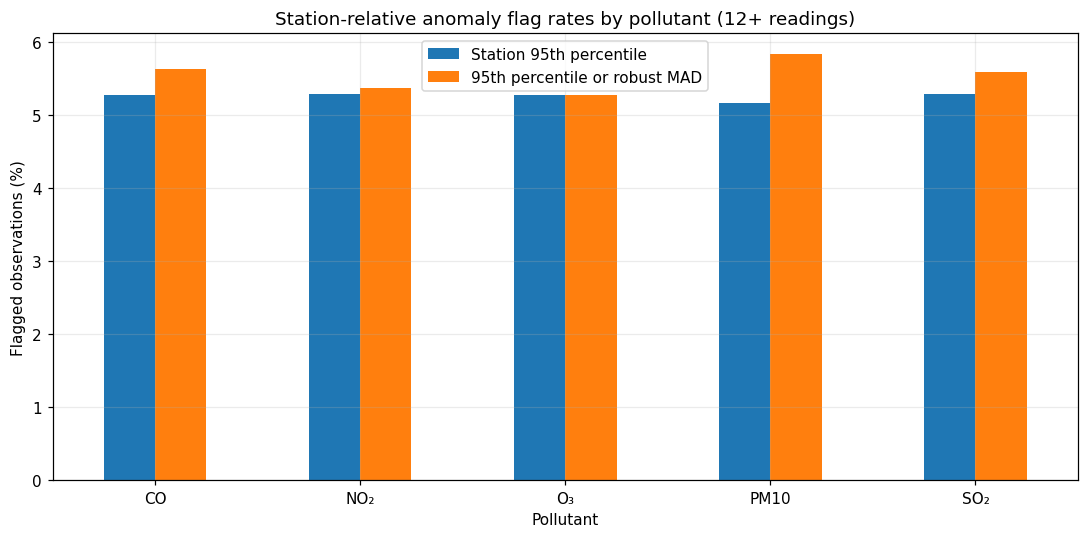

In [23]:
# Flag unusual values relative to each station's own distribution.
# The primary flags use >=12 readings. A >=18-reading version is saved as a sensitivity check.

anomaly_parts = []
anomaly_sensitivity_rows = []

for pollutant in POLLUTANTS:
    value_col = f"{pollutant}_mean"
    for threshold in [12, 18]:
        data = pollutant_records(master, pollutant, threshold).copy()
        if data.empty:
            continue
        data["value"] = data[value_col]
        data["station_p95"] = data.groupby("station_id")["value"].transform(lambda x: x.quantile(0.95))
        data["station_median"] = data.groupby("station_id")["value"].transform("median")
        data["station_mad"] = data.groupby("station_id")["value"].transform(
            lambda x: (x - x.median()).abs().median()
        )
        data["robust_z"] = np.where(
            data.station_mad > 0,
            0.6745 * (data.value - data.station_median) / data.station_mad,
            np.nan,
        )
        data["station_p95_flag"] = data.value > data.station_p95
        data["mad_flag"] = data.robust_z > 3.5
        data["anomaly_flag"] = data.station_p95_flag | data.mad_flag

        anomaly_sensitivity_rows.append({
            "pollutant": POLLUTANT_LABELS[pollutant],
            "minimum_readings": threshold,
            "valid_observations": len(data),
            "station_p95_flags": int(data.station_p95_flag.sum()),
            "station_p95_flag_rate_pct": 100 * data.station_p95_flag.mean(),
            "MAD_flags": int(data.mad_flag.sum()),
            "either_flag_count": int(data.anomaly_flag.sum()),
            "either_flag_rate_pct": 100 * data.anomaly_flag.mean(),
        })

        if threshold == MIN_READINGS_MAIN:
            anomaly_parts.append(data[[
                "station_id", "station_name", "day", "value", f"{pollutant}_readings",
                "station_p95", "robust_z", "station_p95_flag", "mad_flag", "anomaly_flag",
                "temperature_mean", "humidity_mean", "pressure_mean", "wind_speed_mean",
                "wind_direction_mean", "rainfall_total", "era5_grid_cell"
            ]].rename(columns={f"{pollutant}_readings": "reading_count"}).assign(
                pollutant=POLLUTANT_LABELS[pollutant]
            ))

anomaly_flags = pd.concat(anomaly_parts, ignore_index=True)
anomaly_flags.to_csv(TABLE_DIR / "station_relative_anomaly_flags_12plus.csv", index=False)

anomaly_summary = anomaly_flags.groupby("pollutant").agg(
    reliable_observations=("value", "count"),
    p95_flags=("station_p95_flag", "sum"),
    mad_flags=("mad_flag", "sum"),
    either_flag=("anomaly_flag", "sum"),
).reset_index()
anomaly_summary["p95_flag_rate_pct"] = 100 * anomaly_summary.p95_flags / anomaly_summary.reliable_observations
anomaly_summary["either_flag_rate_pct"] = 100 * anomaly_summary.either_flag / anomaly_summary.reliable_observations

display(anomaly_summary.round(2))
anomaly_summary.to_csv(TABLE_DIR / "anomaly_flag_summary_12plus.csv", index=False)

anomaly_sensitivity = pd.DataFrame(anomaly_sensitivity_rows)
display(anomaly_sensitivity.round(2))
anomaly_sensitivity.to_csv(TABLE_DIR / "anomaly_support_sensitivity_12_vs_18.csv", index=False)

# Plot rates, not just counts, because pollutant availability differs substantially.
plot_data = anomaly_summary.set_index("pollutant")[["p95_flag_rate_pct", "either_flag_rate_pct"]]
ax = plot_data.plot(kind="bar", figsize=(10, 5))
ax.set_title("Station-relative anomaly flag rates by pollutant (12+ readings)")
ax.set_xlabel("Pollutant")
ax.set_ylabel("Flagged observations (%)")
ax.legend(["Station 95th percentile", "95th percentile or robust MAD"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "15_anomaly_flag_rates.png", bbox_inches="tight")
plt.show()


**Step 23 result:** We now have a reproducible station-relative anomaly table. The 95th-percentile method flags approximately the upper tail by design; it should not be presented as a validated environmental-event label.

## Step 24 — Distinguish regional from station-specific anomaly days

For each pollutant, use only station-days with at least 12 hourly readings. A station is flagged when its value exceeds its own 95th percentile. A regional statistical-anomaly day requires at least 8 stations reporting and at least 25% of those stations flagged. We also report a rough 5%-tail chance baseline and a separate PM10 >150 numeric sensitivity check; the latter is not called a regulatory exceedance because the supplied OpenAQ file does not document concentration units.


In [24]:
from scipy.stats import binom

regional_rows = []
for pollutant in POLLUTANTS:
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN).copy()
    value_col = f"{pollutant}_mean"
    data["station_p95"] = data.groupby("station_id")[value_col].transform(lambda x: x.quantile(0.95))
    data["station_p95_flag"] = data[value_col] > data.station_p95

    daily_events = data.groupby("day").agg(
        stations_reporting=("station_id", "nunique"),
        stations_flagged=("station_p95_flag", "sum"),
        network_median=(value_col, "median"),
        network_mean=(value_col, "mean"),
    ).reset_index()
    daily_events["flag_fraction"] = daily_events.stations_flagged / daily_events.stations_reporting
    daily_events["regional_anomaly_day"] = (
        daily_events.stations_reporting.ge(8) & daily_events.flag_fraction.ge(0.25)
    )
    # Approximate independence benchmark: each station has a 5% upper-tail flag rate.
    # This is a descriptive chance baseline, not a formal inferential p-value.
    daily_events["chance_tail_p05"] = [
        binom.sf(int(k) - 1, int(n), 0.05)
        for k, n in zip(daily_events.stations_flagged, daily_events.stations_reporting)
    ]
    daily_events["pollutant"] = POLLUTANT_LABELS[pollutant]
    regional_rows.append(daily_events)

regional_days = pd.concat(regional_rows, ignore_index=True)
regional_days.to_csv(TABLE_DIR / "regional_vs_station_specific_anomaly_days.csv", index=False)

regional_summary = regional_days.groupby("pollutant").agg(
    dates_with_enough_stations=("stations_reporting", lambda x: int(x.ge(8).sum())),
    regional_anomaly_days=("regional_anomaly_day", "sum"),
    maximum_flagged_stations=("stations_flagged", "max"),
    median_flag_fraction=("flag_fraction", "median"),
).reset_index()
display(regional_summary.round(3))
regional_summary.to_csv(TABLE_DIR / "regional_anomaly_summary.csv", index=False)

# For each pollutant, identify whether a flagged station-day is part of a regional flagged day.
regional_lookup = regional_days[["pollutant", "day", "regional_anomaly_day", "stations_reporting", "stations_flagged", "flag_fraction"]]
station_anomalies = anomaly_flags.merge(
    regional_lookup, on=["pollutant", "day"], how="left", validate="many_to_one"
)
station_anomalies["station_specific_flag"] = (
    station_anomalies.anomaly_flag & ~station_anomalies.regional_anomaly_day.fillna(False)
)
station_anomalies.to_csv(TABLE_DIR / "station_specific_vs_regional_anomaly_flags.csv", index=False)

# Cross-station synchrony: count days with different shares of stations flagged.
synchrony = regional_days.loc[regional_days.stations_reporting.ge(8)].groupby("pollutant").agg(
    eligible_days=("day", "nunique"),
    days_10pct_or_more=("flag_fraction", lambda x: int(x.ge(0.10).sum())),
    days_25pct_or_more=("flag_fraction", lambda x: int(x.ge(0.25).sum())),
    days_33pct_or_more=("flag_fraction", lambda x: int(x.ge(1/3).sum())),
    days_50pct_or_more=("flag_fraction", lambda x: int(x.ge(0.50).sum())),
).reset_index()
display(synchrony)
synchrony.to_csv(TABLE_DIR / "cross_station_synchrony_by_pollutant.csv", index=False)

# Separate PM10 >150 sensitivity analysis. The OpenAQ file does not document units,
# so this is an exploratory numeric threshold, NOT a confirmed regulatory exceedance.
pm10_valid = pollutant_records(master, "pm10", MIN_READINGS_MAIN).copy()
pm10_valid["above_150_assumed_unit"] = pm10_valid.pm10_mean > 150
pm10_150_days = pm10_valid.groupby("day").agg(
    stations_reporting=("station_id", "nunique"),
    stations_above_150=("above_150_assumed_unit", "sum"),
    network_pm10_median=("pm10_mean", "median"),
).reset_index()
pm10_150_days["share_above_150"] = pm10_150_days.stations_above_150 / pm10_150_days.stations_reporting
pm10_150_days["regional_150_sensitivity"] = (
    pm10_150_days.stations_reporting.ge(8) & pm10_150_days.share_above_150.ge(0.25)
)
pm10_150_days.to_csv(TABLE_DIR / "pm10_150_assumed_threshold_sensitivity.csv", index=False)
print("Top PM10 regional statistical-anomaly days:")
display(regional_days.loc[
    (regional_days.pollutant == "PM10") & regional_days.regional_anomaly_day
].sort_values("flag_fraction", ascending=False).head(15))
print("PM10 >150 sensitivity days (unit not verified):", int(pm10_150_days.regional_150_sensitivity.sum()))


,pollutant,dates_with_enough_stations,regional_anomaly_days,maximum_flagged_stations,median_flag_fraction
0,CO,0,0,3,0.00
1,NO₂,249,15,11,0.00
2,O₃,249,16,10,0.00
3,PM10,248,23,13,0.00
4,SO₂,249,12,10,0.05


,pollutant,eligible_days,days_10pct_or_more,days_25pct_or_more,days_33pct_or_more,days_50pct_or_more
0,NO₂,249,48,15,9,2
1,O₃,249,36,16,12,4
2,PM10,248,40,23,14,3
3,SO₂,249,67,12,3,1


Top PM10 regional statistical-anomaly days:


,day,stations_reporting,stations_flagged,network_median,network_mean,flag_fraction,regional_anomaly_day,chance_tail_p05,pollutant
236,2024-03-25,18,13,230.407051,229.865028,0.722222,True,8.247242e-14,PM10
75,2023-09-20,20,12,159.304348,212.332426,0.600000,True,2.108169e-11,PM10
243,2024-04-30,20,12,170.394737,169.448443,0.600000,True,2.108169e-11,PM10
83,2023-09-28,20,9,118.950535,155.936459,0.450000,True,1.979338e-07,PM10
49,2023-08-25,20,9,138.708333,192.836122,0.450000,True,1.979338e-07,PM10
63,2023-09-08,20,8,135.342803,153.867776,0.400000,True,2.856885e-06,PM10
72,2023-09-17,20,8,144.531621,151.724006,0.400000,True,2.856885e-06,PM10
233,2024-03-17,20,8,134.895833,140.508333,0.400000,True,2.856885e-06,PM10
50,2023-08-26,19,7,140.782609,200.577154,0.368421,True,2.306492e-05,PM10
53,2023-08-29,20,7,122.630435,146.115537,0.350000,True,3.394617e-05,PM10


PM10 >150 sensitivity days (unit not verified): 28


**Step 24 result:** The synchrony analysis distinguishes isolated station flags from dates when several stations are unusual at once. The 5%-tail chance calculation is only a rough independence benchmark: stations may share sources, conditions and ERA5 grid cells. Statistical flags are screening tools, not confirmed environmental incidents.


## Step 25 — Compare regional PM10 anomaly days with weather at day level

A regional event is a date-level outcome, so weather must not be counted once per station when several stations share the same ERA5 grid cell. We first keep one weather record per distinct grid cell and date, then summarize the daily grid-cell estimates. Comparisons are shown overall and within two broad time windows to reduce seasonal confounding. The event-day counts are small, so these comparisons are exploratory.


In [25]:
# Compare regional PM10 anomaly days with other days at the DATE level.
# Weather is first reduced to one value per ERA5 grid cell per date, so stations
# sharing a grid cell do not multiply the same weather observation.
from scipy.stats import mannwhitneyu

weather_compare_variables = [
    "temperature_mean", "humidity_mean", "dew_point_mean", "pressure_mean",
    "wind_speed_mean", "wind_speed_max", "rainfall_total", "cloud_cover_mean",
    "pressure_change_1d", "wind_speed_change_1d"
]

weather_grid_day = master[["day", "era5_grid_cell"] + weather_compare_variables].dropna(
    subset=["day", "era5_grid_cell"]
).drop_duplicates(["day", "era5_grid_cell"])
weather_by_day = weather_grid_day.groupby("day").agg(
    **{f"{c}_grid_median": (c, "median") for c in weather_compare_variables},
    distinct_grid_cells=("era5_grid_cell", "nunique")
).reset_index()

pm10_day_events = regional_days.loc[regional_days.pollutant.eq("PM10")].copy()
weather_day_analysis = pm10_day_events.merge(
    weather_by_day, on="day", how="left", validate="one_to_one"
)

# Use the two time windows from the independent review to reduce broad seasonal mixing.
window_1_start = pd.Timestamp("2023-08-15")
window_1_end = pd.Timestamp("2023-10-19")
window_2_start = pd.Timestamp("2023-10-20")

weather_day_analysis["season_window"] = "Outside comparison windows"
weather_day_analysis.loc[
    weather_day_analysis.day.between(window_1_start, window_1_end), "season_window"
] = "2023-08-15 to 2023-10-19"
weather_day_analysis.loc[
    weather_day_analysis.day.ge(window_2_start), "season_window"
] = "2023-10-20 onward"

weather_day_analysis.to_csv(TABLE_DIR / "pm10_day_level_weather_and_regional_flags.csv", index=False)

summary_rows = []
for window_name, subset in weather_day_analysis.groupby("season_window", sort=False):
    if window_name == "Outside comparison windows":
        continue
    for variable in weather_compare_variables:
        col = f"{variable}_grid_median"
        event_values = subset.loc[subset.regional_anomaly_day, col].dropna()
        other_values = subset.loc[~subset.regional_anomaly_day, col].dropna()
        if len(event_values) and len(other_values):
            test = mannwhitneyu(event_values, other_values, alternative="two-sided")
            p_value = float(test.pvalue)
        else:
            p_value = np.nan
        summary_rows.append({
            "season_window": window_name,
            "weather_variable": variable,
            "regional_event_days": int(len(event_values)),
            "other_days": int(len(other_values)),
            "regional_event_median": float(event_values.median()) if len(event_values) else np.nan,
            "other_day_median": float(other_values.median()) if len(other_values) else np.nan,
            "median_difference": (
                float(event_values.median() - other_values.median())
                if len(event_values) and len(other_values) else np.nan
            ),
            "mann_whitney_p_exploratory": p_value,
            "median_grid_cells_per_day": float(subset.distinct_grid_cells.median()),
        })

weather_event_summary = pd.DataFrame(summary_rows)
display(weather_event_summary.round(3))
weather_event_summary.to_csv(TABLE_DIR / "weather_during_pm10_regional_days_day_level_season_stratified.csv", index=False)

# Compact event-date list for case studies; one row per date, not one row per station.
event_weather = weather_day_analysis.loc[weather_day_analysis.regional_anomaly_day].copy()
event_weather = event_weather.sort_values(["season_window", "flag_fraction"], ascending=[True, False])
display(event_weather[[
    "day", "season_window", "stations_reporting", "stations_flagged", "flag_fraction",
    "network_median", "distinct_grid_cells"
] + [f"{c}_grid_median" for c in weather_compare_variables]].head(30))
event_weather.to_csv(TABLE_DIR / "pm10_regional_anomaly_day_case_studies.csv", index=False)

print("Regional PM10 days:", int(weather_day_analysis.regional_anomaly_day.sum()))
print("Eligible PM10 dates:", len(weather_day_analysis))
print("Weather is counted once per distinct ERA5 grid cell per date.")
print("Small event-day counts mean the season-stratified comparisons are exploratory.")


,season_window,weather_variable,regional_event_days,other_days,regional_event_median,other_day_median,median_difference,mann_whitney_p_exploratory,median_grid_cells_per_day
0,2023-08-15 to 2023-10-19,temperature_mean,15,36,35.325,34.340,0.985,0.013,11.0
1,2023-08-15 to 2023-10-19,humidity_mean,15,36,53.292,58.479,-5.188,0.109,11.0
2,2023-08-15 to 2023-10-19,dew_point_mean,15,36,24.162,22.546,1.617,0.347,11.0
3,2023-08-15 to 2023-10-19,pressure_mean,15,36,1002.392,1004.019,-1.627,0.025,11.0
4,2023-08-15 to 2023-10-19,wind_speed_mean,15,36,11.421,11.169,0.252,0.901,11.0
5,2023-08-15 to 2023-10-19,wind_speed_max,15,36,21.300,21.950,-0.650,0.438,11.0
6,2023-08-15 to 2023-10-19,rainfall_total,15,36,0.000,0.000,0.000,1.000,11.0
7,2023-08-15 to 2023-10-19,cloud_cover_mean,15,36,5.583,2.708,2.875,0.203,11.0
8,2023-08-15 to 2023-10-19,pressure_change_1d,15,36,0.492,0.125,0.367,0.584,11.0
9,2023-08-15 to 2023-10-19,wind_speed_change_1d,15,36,-0.217,0.415,-0.631,0.812,11.0


,day,season_window,stations_reporting,stations_flagged,flag_fraction,network_median,distinct_grid_cells,temperature_mean_grid_median,humidity_mean_grid_median,dew_point_mean_grid_median,pressure_mean_grid_median,wind_speed_mean_grid_median,wind_speed_max_grid_median,rainfall_total_grid_median,cloud_cover_mean_grid_median,pressure_change_1d_grid_median,wind_speed_change_1d_grid_median
75,2023-09-20,2023-08-15 to 2023-10-19,20,12,0.600000,159.304348,11,35.866667,53.291667,24.587500,1004.062500,13.033333,22.7,0.0,59.375000,1.850000,3.041667
49,2023-08-25,2023-08-15 to 2023-10-19,20,9,0.450000,138.708333,11,37.150000,57.500000,26.070833,997.158333,9.625000,17.7,0.0,13.500000,-1.679167,0.441667
83,2023-09-28,2023-08-15 to 2023-10-19,20,9,0.450000,118.950535,11,33.462500,40.666667,17.141667,1007.900000,14.345833,21.0,0.0,0.000000,1.095833,0.958333
63,2023-09-08,2023-08-15 to 2023-10-19,20,8,0.400000,135.342803,11,35.733333,44.125000,20.479167,1003.183333,14.995833,24.2,0.0,0.625000,0.525000,-0.216667
72,2023-09-17,2023-08-15 to 2023-10-19,20,8,0.400000,144.531621,11,34.287500,60.583333,24.520833,1001.158333,11.420833,21.3,0.0,22.875000,-0.429167,-1.308333
50,2023-08-26,2023-08-15 to 2023-10-19,19,7,0.368421,140.782609,11,37.929167,52.958333,24.162500,997.962500,10.695833,22.5,0.0,21.666667,0.779167,2.770833
53,2023-08-29,2023-08-15 to 2023-10-19,20,7,0.350000,122.630435,11,36.708333,45.041667,20.695833,999.370833,11.145833,20.1,0.0,2.458333,-0.404167,-1.704167
64,2023-09-09,2023-08-15 to 2023-10-19,20,7,0.350000,138.872024,11,35.112500,48.583333,20.470833,1002.862500,12.312500,23.6,0.0,0.166667,-0.475000,-1.491667
74,2023-09-19,2023-08-15 to 2023-10-19,20,7,0.350000,141.878788,11,35.258333,56.541667,24.320833,1002.270833,9.487500,22.0,0.0,52.708333,1.537500,-0.879167
80,2023-09-25,2023-08-15 to 2023-10-19,20,7,0.350000,119.280632,11,34.358333,52.416667,22.437500,1004.670833,11.741667,20.6,0.0,0.916667,-0.591667,-0.400000


Regional PM10 days: 23
Eligible PM10 dates: 249
Weather is counted once per distinct ERA5 grid cell per date.
Small event-day counts mean the season-stratified comparisons are exploratory.


**Step 25 result:** Weather comparisons now use one observation per calendar date, with each distinct ERA5 grid cell counted once. Seasonal-window comparisons reduce broad seasonal mixing, but do not remove all confounding. Very small event-day counts, especially in the later window, mean that p-values and median differences must be interpreted as exploratory rather than definitive.


## Step 26 — Compare station-month-adjusted weather correlations

We report both pooled and station-month-adjusted Spearman correlations on the ≥12-reading subset. The adjustment subtracts each station's monthly median from both variables before calculating correlation. We also report the number of distinct dates and ERA5 grid cells represented. Because several stations share weather grid cells, station-day row counts are not independent weather sample sizes; no row-level significance claim is made.


,pollutant,weather_variable,station_day_pairs,unique_dates,unique_era5_grid_cells,station_month_groups,pooled_spearman,station_month_adjusted_spearman
0,PM10,temperature_mean,4834,249,11,319,0.455,0.203
1,PM10,humidity_mean,4834,249,11,319,-0.162,-0.090
2,PM10,dew_point_mean,4834,249,11,319,0.325,0.055
3,PM10,rainfall_total,4834,249,11,319,-0.094,-0.028
4,PM10,pressure_mean,4834,249,11,319,-0.435,-0.198
5,PM10,wind_speed_mean,4834,249,11,319,0.084,0.162
6,PM10,wind_speed_max,4834,249,11,319,0.208,0.179
7,PM10,cloud_cover_mean,4834,249,11,319,-0.077,0.079
8,NO₂,temperature_mean,4918,250,11,319,-0.063,-0.101
9,NO₂,humidity_mean,4918,250,11,319,0.086,-0.182


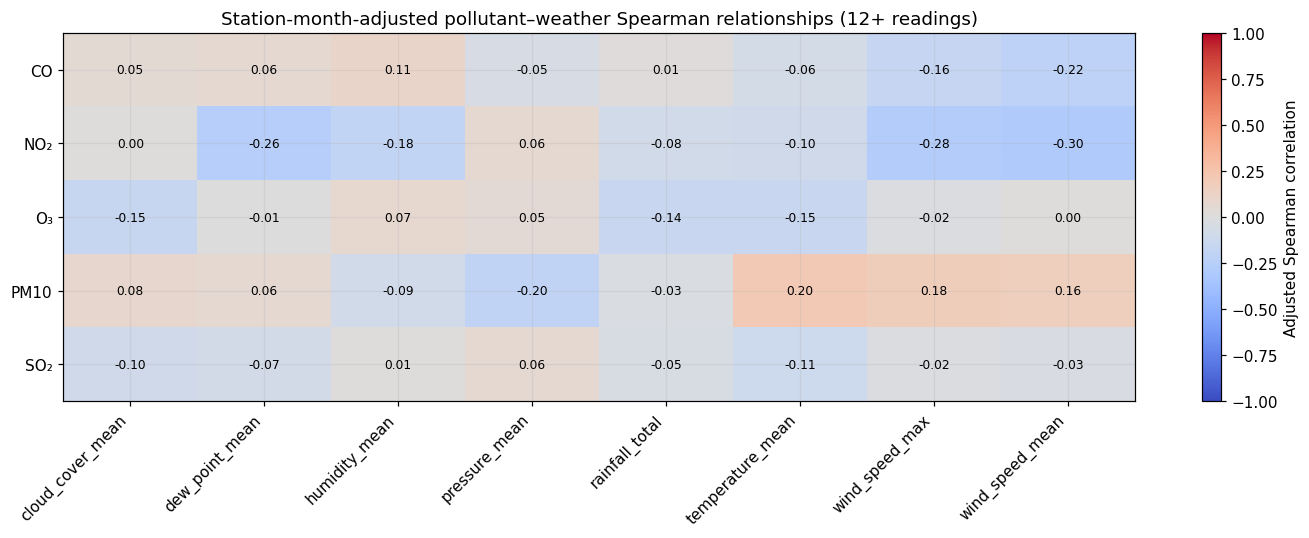

Interpret correlations descriptively. Do not calculate row-level p-values as if all station-days had independent weather.
The effective spatial weather support is the number of distinct ERA5 grid cells, not the number of station-day rows.


In [26]:
adjusted_rows = []
for pollutant in POLLUTANTS:
    data = pollutant_records(master, pollutant, MIN_READINGS_MAIN).copy()
    data["station_month"] = data.station_id.astype(str) + "_" + data.month_start.astype(str)
    for weather_variable in weather_for_corr:
        pair = data[[f"{pollutant}_mean", weather_variable, "station_month", "day", "era5_grid_cell"]].dropna()
        if pair.empty:
            continue
        pooled_rho = pair[f"{pollutant}_mean"].corr(pair[weather_variable], method="spearman")
        pair["pollution_adjusted"] = pair[f"{pollutant}_mean"] - pair.groupby("station_month")[f"{pollutant}_mean"].transform("median")
        pair["weather_adjusted"] = pair[weather_variable] - pair.groupby("station_month")[weather_variable].transform("median")
        adjusted_rho = pair.pollution_adjusted.corr(pair.weather_adjusted, method="spearman")
        adjusted_rows.append({
            "pollutant": POLLUTANT_LABELS[pollutant],
            "weather_variable": weather_variable,
            "station_day_pairs": len(pair),
            "unique_dates": pair.day.nunique(),
            "unique_era5_grid_cells": pair.era5_grid_cell.nunique(),
            "station_month_groups": pair.station_month.nunique(),
            "pooled_spearman": pooled_rho,
            "station_month_adjusted_spearman": adjusted_rho,
        })

station_month_adjusted = pd.DataFrame(adjusted_rows)
display(station_month_adjusted.round(3))
station_month_adjusted.to_csv(TABLE_DIR / "station_month_adjusted_weather_correlations.csv", index=False)

heatmap = station_month_adjusted.pivot(
    index="pollutant", columns="weather_variable", values="station_month_adjusted_spearman"
)
fig, ax = plt.subplots(figsize=(13, 5))
image = ax.imshow(heatmap, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_yticks(range(len(heatmap.index))); ax.set_yticklabels(heatmap.index)
ax.set_xticks(range(len(heatmap.columns))); ax.set_xticklabels(heatmap.columns, rotation=45, ha="right")
ax.set_title("Station-month-adjusted pollutant–weather Spearman relationships (12+ readings)")
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        value = heatmap.iloc[i, j]
        ax.text(j, i, f"{value:.2f}" if pd.notna(value) else "NA", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Adjusted Spearman correlation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_pollutant_weather_adjusted_correlations.png", bbox_inches="tight")
plt.show()

print("Interpret correlations descriptively. Do not calculate row-level p-values as if all station-days had independent weather.")
print("The effective spatial weather support is the number of distinct ERA5 grid cells, not the number of station-day rows.")


**Step 26 result:** Use the station-month-adjusted correlations as the primary descriptive weather result and pooled correlations as context. The number of station-day pairs is not an independent sample size because several stations share ERA5 grid cells and adjacent dates are temporally related. These remain associations, not causal estimates.


## Step 27 — Check whether the main findings depend on the reading threshold

We compare selected pooled pollutant and weather correlations using all available observations, ≥12 readings, and ≥18 readings. If the sign or size changes substantially, the report should make the support sensitivity explicit.

In [27]:
threshold_corr_rows = []
for pollutant in POLLUTANTS:
    for threshold_name, threshold in [("All available", 1), ("12+ readings", 12), ("18+ readings", 18)]:
        data = master.loc[
            master[f"{pollutant}_mean"].notna() & master[f"{pollutant}_readings"].ge(threshold)
        ].copy()
        data["station_month"] = data.station_id.astype(str) + "_" + data.month_start.astype(str)
        for weather_variable in ["temperature_mean", "pressure_mean", "wind_speed_mean", "humidity_mean"]:
            pair = data[[f"{pollutant}_mean", weather_variable, "station_month", "day", "era5_grid_cell"]].dropna()
            if pair.empty:
                continue
            pooled = pair[f"{pollutant}_mean"].corr(pair[weather_variable], method="spearman")
            pair["pollution_adjusted"] = pair[f"{pollutant}_mean"] - pair.groupby("station_month")[f"{pollutant}_mean"].transform("median")
            pair["weather_adjusted"] = pair[weather_variable] - pair.groupby("station_month")[weather_variable].transform("median")
            adjusted = pair.pollution_adjusted.corr(pair.weather_adjusted, method="spearman")
            threshold_corr_rows.append({
                "pollutant": POLLUTANT_LABELS[pollutant],
                "support_subset": threshold_name,
                "weather_variable": weather_variable,
                "station_day_pairs": len(pair),
                "unique_dates": pair.day.nunique(),
                "unique_era5_grid_cells": pair.era5_grid_cell.nunique(),
                "pooled_spearman": pooled,
                "station_month_adjusted_spearman": adjusted,
            })

threshold_correlations = pd.DataFrame(threshold_corr_rows)
display(threshold_correlations.round(3))
threshold_correlations.to_csv(TABLE_DIR / "weather_correlation_support_sensitivity.csv", index=False)
print("Use the 12+ and 18+ rows as the main and strict sensitivity analyses. All-available rows are contextual only.")


,pollutant,support_subset,weather_variable,station_day_pairs,unique_dates,unique_era5_grid_cells,pooled_spearman,station_month_adjusted_spearman
0,PM10,All available,temperature_mean,7060,365,11,0.474,0.219
1,PM10,All available,pressure_mean,7060,365,11,-0.448,-0.156
2,PM10,All available,wind_speed_mean,7060,365,11,0.104,0.160
3,PM10,All available,humidity_mean,7060,365,11,-0.187,-0.061
4,PM10,12+ readings,temperature_mean,4834,249,11,0.455,0.203
5,PM10,12+ readings,pressure_mean,4834,249,11,-0.435,-0.198
6,PM10,12+ readings,wind_speed_mean,4834,249,11,0.084,0.162
7,PM10,12+ readings,humidity_mean,4834,249,11,-0.162,-0.090
8,PM10,18+ readings,temperature_mean,3524,188,11,0.482,0.199
9,PM10,18+ readings,pressure_mean,3524,188,11,-0.470,-0.226


Use the 12+ and 18+ rows as the main and strict sensitivity analyses. All-available rows are contextual only.


**Step 27 result:** The support-sensitivity table helps identify which weather relationships are robust to the choice of minimum hourly reading count.

## Step 28 — Summary of important quality checks

We consolidate the checks needed for the report: key uniqueness, station/date coverage, weather alignment, hourly completeness, missing pollutant coverage, and shared ERA5 grid cells.

In [28]:
quality_report = {
    "pollution_source_rows_after_exact_deduplication": int(len(daily)),
    "pollution_duplicate_station_day_pollutant_keys": int(daily.duplicated(["station_id", "day", "parameter"]).sum()),
    "station_metadata_rows": int(len(stations)),
    "stations_in_master": int(master.station_id.nunique()),
    "master_station_day_rows": int(len(master)),
    "calendar_days": int(master.day.nunique()),
    "pollution_dates_with_any_data": int(daily.day.nunique()),
    "master_rows_with_any_pollution": int(master.any_pollution_record.sum()),
    "hourly_weather_rows": int(len(hourly)),
    "hourly_weather_stations": int(hourly.station_id.nunique()),
    "unique_era5_grid_cells": int(grid_by_station.era5_grid_cell.nunique()),
    "weather_daily_station_days": int(len(weather_from_hourly)),
    "daily_weather_rows_matching_hourly": int((comparison._merge == "both").sum()),
    "daily_weather_rows_not_matching_hourly": int((comparison._merge != "both").sum()),
    "master_weather_missing_rows": int(master.temperature_mean.isna().sum()),
    "master_rows_with_all_5_pollutants": int((master.n_pollutants_available == 5).sum()),
    "master_rows_with_all_5_pollutants_12plus": int((master.n_pollutants_reliable_12plus == 5).sum()),
}
with open(TABLE_DIR / "quality_report.json", "w", encoding="utf-8") as f:
    json.dump(quality_report, f, indent=2, default=str)
display(pd.DataFrame([quality_report]).T.rename(columns={0: "value"}))

,value
pollution_source_rows_after_exact_deduplication,28714
pollution_duplicate_station_day_pollutant_keys,0
station_metadata_rows,20
stations_in_master,20
master_station_day_rows,11400
calendar_days,570
pollution_dates_with_any_data,366
master_rows_with_any_pollution,7129
hourly_weather_rows,273600
hourly_weather_stations,20


**Step 28 result:** This report provides the headline dataset-quality numbers and confirms whether the master dataset is ready to be shared for downstream work.

## Step 29 — Create chronological partitions for downstream modelling

The partitions use the same explicit date boundaries as the currently shared `model_table.csv`, rather than calculating 70/15/15 from all 570 calendar days. The full master remains available for EDA; dates outside the shared PM10 model window are labelled `eda_only`. Confirm the boundaries with Noor and Ali before modelling. The partitions preserve raw values and missingness; model-specific imputation, scaling and encoding must be fitted on training data only.


In [29]:
# Use the same chronological boundaries as the current shared model_table.csv.
# If Noor/Ali agree to different dates, change ONLY these six dates and rerun this cell.
TRAIN_START = pd.Timestamp("2023-08-31")
TRAIN_END = pd.Timestamp("2023-11-30")
VALIDATION_START = pd.Timestamp("2023-12-01")
VALIDATION_END = pd.Timestamp("2023-12-31")
TEST_START = pd.Timestamp("2024-01-01")
TEST_END = pd.Timestamp("2024-02-24")

# Keep the complete master for EDA. Dates outside the shared modelling window are labelled EDA-only.
master["split"] = "eda_only"
master.loc[master.day.between(TRAIN_START, TRAIN_END), "split"] = "train"
master.loc[master.day.between(VALIDATION_START, VALIDATION_END), "split"] = "validation"
master.loc[master.day.between(TEST_START, TEST_END), "split"] = "test"

split_summary = master.groupby("split").agg(
    station_day_rows=("day", "size"),
    distinct_calendar_dates=("day", "nunique"),
    first_date=("day", "min"),
    last_date=("day", "max"),
    rows_with_any_pollution=("any_pollution_record", "sum"),
    pm10_12plus_station_days=("pm10_readings", lambda x: int(x.ge(12).sum())),
    pm10_18plus_station_days=("pm10_readings", lambda x: int(x.ge(18).sum())),
).reindex(["eda_only", "train", "validation", "test"]).reset_index()

# Count the dates with at least one usable PM10 observation, not just calendar dates.
valid_pm10 = master.loc[master.pm10_readings.ge(MIN_READINGS_MAIN)]
valid_pm10_dates = valid_pm10.groupby("split").day.nunique().rename("dates_with_pm10_12plus")
split_summary = split_summary.merge(valid_pm10_dates, on="split", how="left")
split_summary["dates_with_pm10_12plus"] = split_summary.dates_with_pm10_12plus.fillna(0).astype(int)

display(split_summary)
split_summary.to_csv(TABLE_DIR / "chronological_split_summary.csv", index=False)

master.to_csv(OUTPUT_DIR / "master_station_day_wide_with_split.csv", index=False)
long_master.to_csv(OUTPUT_DIR / "master_pollution_long_with_weather.csv", index=False)
for split_name in ["train", "validation", "test"]:
    master.loc[master.split == split_name].to_csv(
        OUTPUT_DIR / f"master_station_day_{split_name}.csv", index=False
    )

print("The split boundaries match the currently shared model_table.csv.")
print("All dates outside that model window remain in the full master and are labelled 'eda_only'.")
print("Do not change these cutoffs independently of Noor and Ali.")


,split,station_day_rows,distinct_calendar_dates,first_date,last_date,rows_with_any_pollution,pm10_12plus_station_days,pm10_18plus_station_days,dates_with_pm10_12plus
0,eda_only,7840,392,2022-10-29,2024-05-20,3730,1613,462,84
1,train,1840,92,2023-08-31,2023-11-30,1680,1579,1449,81
2,validation,620,31,2023-12-01,2023-12-31,620,608,592,31
3,test,1100,55,2024-01-01,2024-02-24,1099,1034,1021,53


The split boundaries match the currently shared model_table.csv.
All dates outside that model window remain in the full master and are labelled 'eda_only'.
Do not change these cutoffs independently of Noor and Ali.


**Step 29 result:** The full master and aligned chronological partitions are saved. The `eda_only` label preserves dates outside the current shared forecasting window. These files remain untransformed master-data partitions, not model-ready matrices. Noor and Ali should use the same agreed date cutoffs and then fit model-specific preprocessing on training data only.


## Step 30 — Export a data dictionary and source files

We copy the source files used in this notebook into the output package so the analysis can be reproduced.

In [30]:
data_dictionary = pd.DataFrame([
    ["station_id", "OpenAQ station identifier", "identifier"],
    ["station_name", "Monitoring station name", "categorical/location"],
    ["day", "Calendar date used to join OpenAQ daily records and ERA5 local-day summaries", "date; source timezone caveat applies"],
    ["lat", "OpenAQ monitoring station latitude", "degrees"],
    ["lon", "OpenAQ monitoring station longitude", "degrees"],
    ["*_mean", "Daily mean concentration for each pollutant", "unit not specified in supplied OpenAQ CSV"],
    ["*_max", "Daily maximum concentration for each pollutant", "unit not specified in supplied OpenAQ CSV"],
    ["*_readings", "Number of hourly pollutant readings contributing to the daily record", "count"],
    ["*_available", "1 when the pollutant daily mean is present", "quality indicator"],
    ["*_sampling_regime", "Pollutant-specific support category: no record, <12, 12-17, or 18+ readings", "categorical quality label"],
    ["*_low_support_lt12", "1 when pollutant record has fewer than 12 readings", "quality flag"],
    ["*_support_12_to_17", "1 when pollutant record has 12 to 17 readings", "quality flag"],
    ["*_support_18_plus", "1 when pollutant record has at least 18 readings", "quality flag"],
    ["temperature_mean/min/max", "Daily temperature summaries from hourly ERA5", "°C"],
    ["humidity_mean", "Daily mean relative humidity from ERA5", "%"],
    ["dew_point_mean", "Daily mean dew point from ERA5", "°C"],
    ["rainfall_total", "Daily precipitation total from ERA5", "mm"],
    ["pressure_mean", "Daily mean sea-level pressure from ERA5", "hPa"],
    ["wind_speed_mean/max", "Daily wind speed summaries from ERA5", "km/h"],
    ["wind_direction_mean", "Daily circular mean wind direction from ERA5", "degrees clockwise from north"],
    ["wind_direction_sin/cos", "Circular encoding of wind direction", "dimensionless"],
    ["pressure_change_1d", "Change in daily mean pressure from the previous calendar day at the same station/grid", "hPa/day"],
    ["wind_speed_change_1d", "Change in daily mean wind speed from the previous calendar day", "km/h/day"],
    ["cloud_cover_mean", "Daily mean cloud cover from ERA5", "%"],
    ["era5_grid_cell", "ERA5 grid cell shared by one or more nearby OpenAQ stations", "grid identifier"],
    ["n_pollutants_available", "Number of pollutants available at a station-day", "count"],
    ["n_pollutants_reliable_12plus", "Number of pollutants with at least 12 readings", "count"],
    ["n_pollutants_low_support", "Number of pollutants with fewer than 12 readings", "count"],
    ["n_pollutants_18plus", "Number of pollutants with at least 18 readings", "count"],
    ["wind_sector", "Broad 8-sector category based on daily circular mean wind direction", "categorical"],
    ["split", "Shared chronological period; dates outside modelling window are eda_only", "train/validation/test/eda_only"],
], columns=["column_or_pattern", "meaning", "unit_or_type"])
data_dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)

for source_file in [DAILY_FILE, STATIONS_FILE, WEATHER_DAILY_FILE, WEATHER_HOURLY_FILE]:
    shutil.copy2(source_file, INPUT_DIR / source_file.name)

print("Master dataset saved:", OUTPUT_DIR / "master_station_day_wide_with_split.csv")
print("Input files copied:", len(list(INPUT_DIR.glob("*.csv"))))
display(data_dictionary)


Master dataset saved: /content/abudhabi_openaq_eda_outputs/master_station_day_wide_with_split.csv
Input files copied: 4


,column_or_pattern,meaning,unit_or_type
0,station_id,OpenAQ station identifier,identifier
1,station_name,Monitoring station name,categorical/location
2,day,Calendar date used to join OpenAQ daily record...,date; source timezone caveat applies
3,lat,OpenAQ monitoring station latitude,degrees
4,lon,OpenAQ monitoring station longitude,degrees
5,*_mean,Daily mean concentration for each pollutant,unit not specified in supplied OpenAQ CSV
6,*_max,Daily maximum concentration for each pollutant,unit not specified in supplied OpenAQ CSV
7,*_readings,Number of hourly pollutant readings contributi...,count
8,*_available,1 when the pollutant daily mean is present,quality indicator
9,*_sampling_regime,Pollutant-specific support category: no record...,categorical quality label


**Step 30 result:** The package now includes the four input files, the wide station-day master, the enriched long-format data, chronological master partitions, and a data dictionary.

## Step 31 — Build the board-ready figure pack

The figures already saved in the `figures` folder are the presentation-ready outputs. This cell builds a single PDF containing the key plots so you do not need to screenshot figures manually.

In [31]:
from matplotlib.backends.backend_pdf import PdfPages

figure_files = sorted(FIGURE_DIR.glob("*.png"))
pdf_path = OUTPUT_DIR / "AbuDhabi_AirPollution_EDA_FigurePack.pdf"
with PdfPages(pdf_path) as pdf:
    # Cover page
    fig = plt.figure(figsize=(11.7, 8.3))
    fig.text(0.08, 0.75, "Abu Dhabi Air Pollution", fontsize=28, weight="bold")
    fig.text(0.08, 0.65, "OpenAQ daily measurements + ERA5 weather", fontsize=17)
    fig.text(0.08, 0.52, f"Master dataset: {len(master):,} station-days across {master.station_id.nunique()} stations", fontsize=13)
    fig.text(0.08, 0.44, f"Pollution period: {master.day.min().date()} to {master.day.max().date()}", fontsize=13)
    fig.text(0.08, 0.32, "Interpretation note: ERA5 values are gridded reanalysis estimates; OpenAQ daily pollution values do not identify the exact hour of a spike.", fontsize=10, wrap=True)
    plt.axis("off")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    for file in figure_files:
        image = plt.imread(file)
        fig, ax = plt.subplots(figsize=(11.7, 8.3))
        ax.imshow(image)
        ax.axis("off")
        fig.suptitle(file.stem.replace("_", " "), fontsize=14, y=0.98)
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print("PDF figure pack:", pdf_path)
print("Figures included:", len(figure_files))

PDF figure pack: /content/abudhabi_openaq_eda_outputs/AbuDhabi_AirPollution_EDA_FigurePack.pdf
Figures included: 15


**Step 31 result:** A single PDF figure pack is ready for review or presentation. Individual high-resolution PNGs remain available for slides.

## Step 32 — Create a concise run summary and ZIP package

The final package includes the source files, master data, EDA tables, all figures, the PDF figure pack, and the executed notebook.

In [32]:
run_summary = {
    "project": "Abu Dhabi OpenAQ + ERA5 EDA",
    "annual_dataset_included": False,
    "pollution_rows_source": int(len(daily)),
    "master_station_day_rows": int(len(master)),
    "stations": int(master.station_id.nunique()),
    "calendar_days": int(master.day.nunique()),
    "pollution_period_start": str(master.day.min().date()),
    "pollution_period_end": str(master.day.max().date()),
    "hourly_weather_rows": int(len(hourly)),
    "distinct_era5_grid_cells": int(grid_by_station.era5_grid_cell.nunique()),
    "weather_reaggregation_matches_daily_file": bool(
        (comparison._merge == "both").all() and
        weather_alignment_audit["matches_within_1e-6"].all()
    ),
    "main_reliable_reading_threshold": MIN_READINGS_MAIN,
    "strict_sensitivity_threshold": MIN_READINGS_STRICT,
    "number_of_figures": len(list(FIGURE_DIR.glob("*.png"))),
}
with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2)

readme = """ABU DHABI OPENAQ + ERA5 EDA PACKAGE\n\nINPUTS USED (annual data intentionally excluded):\n- OpenAQ daily pollution CSV\n- OpenAQ station metadata CSV\n- ERA5 daily weather CSV\n- ERA5 hourly weather CSV\n\nMAIN OUTPUTS:\n- master_station_day_wide_with_split.csv: full station x calendar-day master with pollutants, weather, quality flags, and chronological split labels\n- master_pollution_long_with_weather.csv: original long-form pollutant observations enriched with station/weather data\n- master_station_day_train.csv / validation.csv / test.csv: chronological master partitions (not transformed model matrices)\n- figures/: high-resolution EDA figures\n- tables/: quality reports, summaries, correlations, anomaly flags, and event tables\n- AbuDhabi_AirPollution_EDA_FigurePack.pdf: consolidated visual report\n- data_dictionary.csv: master field definitions\n- input_files/: exact source CSVs used in this run\n\nQUALITY NOTES:\n- All pollution rows are retained in the master. Reading support is flagged, not silently filtered.
- Main EDA uses >=12 hourly readings per pollutant; >=18 is a sensitivity check.
- ERA5 hourly data was re-aggregated to station-day and compared with the supplied daily weather file.
- ERA5 is gridded reanalysis, not direct station weather. Some stations share ERA5 grid cells.
- The daily OpenAQ file does not include exact pollution event hours; hourly weather describes the date but cannot identify the exact hour of a daily pollution spike.
- Pollutant units are not stated in the supplied OpenAQ CSV; verify from source metadata before regulatory claims.
- Chronological master splits are raw data partitions. Fit model-specific imputation/encoding/scaling on training data only after the modelling target is finalized.
"""
(OUTPUT_DIR / "README.txt").write_text(readme, encoding="utf-8")

zip_path = BASE_DIR / "AbuDhabi_OpenAQ_ERA5_Improved_EDA_Package.zip"
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file in OUTPUT_DIR.rglob("*"):
        if file.is_file():
            archive.write(file, file.relative_to(OUTPUT_DIR.parent))

print("\nFINAL PACKAGE")
print("Output folder:", OUTPUT_DIR)
print("ZIP:", zip_path)
print("Master rows:", len(master))
print("Master columns:", master.shape[1])
print("Figures:", len(list(FIGURE_DIR.glob("*.png"))))
print("Tables:", len(list(TABLE_DIR.glob("*.csv"))))
print("ZIP size (MB):", round(zip_path.stat().st_size / 1024**2, 2))


FINAL PACKAGE
Output folder: /content/abudhabi_openaq_eda_outputs
ZIP: /content/AbuDhabi_OpenAQ_ERA5_Improved_EDA_Package.zip
Master rows: 11400
Master columns: 80
Figures: 15
Tables: 29
ZIP size (MB): 16.32


## Final interpretation checklist

Before using the results in the report:
- State that the main pollutant EDA uses the ≥12-reading subset and show the ≥18-reading sensitivity check.
- Report pollutant coverage separately; do not imply all five pollutants are available at every station-day.
- Report station-month-adjusted correlations alongside pooled correlations.
- Treat statistical anomaly flags as screening tools, not verified pollution incidents.
- Describe ERA5 variables as gridded weather estimates and account for shared grid cells.
- Do not infer exact event-hour weather from daily pollution means/maxima.
- Confirm OpenAQ pollutant units before comparing with official thresholds.
- Do not fit imputers, scalers, encoders, or feature-selection steps on validation/test data.